# Generalized E3SMLE and CESM-SMYLE Atmospheric Skill Maps

This notebook is adapted from `YeagerEA_GMD2022_revision1/f01_fB01_fB03.ipynb` and `YeagerEA_GMD2022_revision1/f02_fB02_fB04.ipynb`. It preserves their lead-time seasonal ACC methodology and map-analysis structure while refactoring data access for the E3SM and CESM-SMYLE comparison and generalizing the workflow across fields.

This notebook computes and plots seasonal skill for `TREFHT`, `TS`, `PRECT`, or `PSL` using the same workflow. Ocean-realm fields (e.g. `SST`) use the same pipeline but live in the companion notebook `1a_ocn_leadtime_acc_skill_map.ipynb`.

Change only one line in the configuration cell below:

```python
# field = "TREFHT"  # surface air temperature
# field = "TS"      # all-surface radiative/skin temperature
# field = "PRECT" # precipitation
# field = "PSL"   # sea-level pressure
```

Variable-specific observation product, observation variable name, unit conversion, labels, and cache filenames are handled through `VAR_CONFIG`.

For a small archive-backed restart test, set `WORKFLOW_SETTINGS["run"]["smoke_mode"] = True`; this selects one case/month, five years, two leads, and three resampling iterations. All paths and workflow choices are visible in the configuration cells below. The default `inventory` identity mode fingerprints the exact input files by relative path, size, and modification time. For an archive-free restart after an inventory run, set `cache.source_identity_mode="snapshot"` and `prepared_skill.mode="require"`. This trusts the last recorded inventory for the same source request; it does not check for archive changes. Prepared observations are cached too. Use `revision` only as a separate manual identity scheme, updating revision tokens whenever files change; it does not reuse inventory identities. Seasonal `lead_start`/`lead_end` are inclusive, one-based positions (1–8 for 24 monthly leads).


In [29]:
%load_ext autoreload
%autoreload 2
import os
from pathlib import Path
import xarray as xr 
import numpy as np  
import cftime
import copy
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import xesmf as xe
import xskillscore as xs
%matplotlib inline

# import ESP-Lab modules
#from esp_lab import data_access_smyle.py as data_access
from esp_lab import env_paths
from esp_lab import data_access_e3sm as data_access
from esp_lab import data_access_cesm_smyle as smyle_access
from esp_lab import data_access_obs as obs_access
from esp_lab import leadtime_realm_skill
from esp_lab import stats
from esp_lab.leadtime_prepared_cache import (
    build_prepared_skill_dataset,
    cache_status,
    expected_prepared_skill_attrs,
    grid_token,
    open_prepared_skill_dataset,
    prepared_skill_cache_status,
    prepared_skill_path,
    units_token,
    write_prepared_skill_dataset,
)
from esp_lab.leadtime_skill_cache import (
    SkillComparisonCacheLayout,
    acc_superiority_fraction,
    cache_comparison_anomaly,
    expected_skill_cache_attrs,
    file_inventory_digest,
    generate_member_indices,
    load_or_write_member_selection,
    member_selection_attrs,
    source_fingerprint,
    stable_resampling_seed,
    verification_year_token,
    year_number,
)

# import plotting and other utilities from esp_lab.utils (formerly SMYLEutils)
from esp_lab.utils import calendar_utils as cal
from esp_lab.utils import mapplot_utils as maps
from esp_lab.utils import regrid_utils as regrid
from esp_lab.utils import mov_utils as mov
from esp_lab.utils.filename_utils import figure_filename
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf
from esp_lab.utils.resource_utils import ResourceTracker
from esp_lab.utils.unit_conversion import (
    convert_kelvin_to_celsius,
    convert_pa_to_hpa,
    convert_precip_mps_to_mmday,
    no_unit_conversion,
)
from esp_lab.leadtime_plot_utils import (
    add_acc_comparison_markers,
    add_lead_badge,
    add_missing_map_panel,
    add_pointwise_significance_markers,
    seasonal_label,
    style_global_map_axis,
)
from esp_lab.leadtime_validation import check_remove_drift_sample
from esp_lab.leadtime_workflow import (
    compute_skill_lead_range,
    compute_skill_lead_range_batch,
    observation_source_identity,
    ocean_mask_identity,
    resolve_source_revision,
    seasonal_cache_encoding,
)
from esp_lab.paths import leadtime_acc_dir

from esp_lab.utils.dask_util import DaskConfig, get_cluster_client, close_cluster

import os


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Preprocessing:  Data I/O using Dask

### Create Dask Cluster

In [30]:
import dask
from dask.distributed import (
    wait,
    get_client
)
from esp_lab.utils.notebook_resources import restart_notebook_cluster, close_notebook_resources

dask.__version__

# User-adjustable Dask settings (shared login nodes are capped at four workers).
machine_env = "local"
dask_workers = 12

dask_cfg = DaskConfig(cluster_type=machine_env, workers=dask_workers)
cluster, client, workflow_resources = restart_notebook_cluster(
    globals(), lambda: get_cluster_client(dask_cfg)
)

cluster



!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
This can easily exceed memory/CPU limits and crash your Jupyter kernel.
We highly recommend launching Jupyter on an Exclusive Perlmutter Compute Node.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Scheduler: tcp://127.0.0.1:44355
Connected workers: 4
Dashboard: http://127.0.0.1:41275/status


LocalCluster(59ca4c4f, 'tcp://127.0.0.1:44355', workers=4, threads=4, memory=14.90 GiB)

### User setup and workflow configuration

Select the diagnostic field, E3SM cases, run years, paths, cache behavior, regridding, significance settings, and figure options here.

In [31]:
%%time
# -----------------------------------------------------------------------------
# Variable-driven setup + multi-case E3SM hindcast setup
# -----------------------------------------------------------------------------
# Change this one line to switch diagnostics:
#   field = "TREFHT"  -> ERA5 tas, model/obs K -> degC
#   field = "TS"      -> ERA5 ts, model/obs K -> degC
#   field = "PRECT"   -> GPCP PRECT, model m/s -> mm/day
#   field = "PSL"     -> ERA5 psl, model/obs Pa -> hPa

#field = "PRECT"
#field = "TREFHT"
#field = "TS"
field = "PSL"

#output directory (comment out for default setup)
#os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test"
#os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
#os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

# mode for derivation of variables choices: 
# "auto": automatically determine whether to rebuild or use cached results
# "rebuild": force recomputation
# "require": require cached results and fail if not available
derivation_mode = "auto"  

# True to force recomputation of skill metrics, False (default) to use cached results if available
recompute_skill = False 

# True to force recomputation of comparison metrics, False to use cached results if available
recompute_compare = False

# True (default) to remove the trend from the data, False to keep it.
remove_trend = True

# True (default when available) to include CESM-SMYLE ACC in the analysis, False to exclude it.
cesm_smyle_acc_on = True

# Optional common processing end year. None uses the end year from
# run.initialization_years.
YEAR_START = 1980
YEAR_END = 2018
init_months = [2, 5, 8, 11]  # Feb/Aug: Reanalysis only, starts every 5 years (1980-2015)
climatology_years = (1981, 2010)
# Start years each case has for each start month; None = every year YEAR_START-YEAR_END.
# A case is skipped for start months it does not have (e.g. FOSIRL Feb/Aug).
INIT_YEARS_BY_CASE = {
    "E3SM-FOSIRL": {5: None, 11: None},
    # Feb/Aug starts exist every five years, 1980-2015.
    "E3SM-Reanalysis": {2: range(1980, 2016, 5), 5: None, 8: range(1980, 2016, 5), 11: None},
}
        
# Which E3SM case should old single-case cells/variables point to.
E3SM_REFERENCE_CASE = "E3SM-FOSIRL"

# Experiment used as the control in the E3SM case ACC-difference figure.
# Every other configured experiment is plotted as experiment minus control.
ACC_DIFFERENCE_CONTROL = "E3SM-Reanalysis"


# Each field reads its observations from obs_path_pattern: an explicit file path
# or glob (e.g. one file per year), loaded by
# obs_access.get_monthly_data_from_pattern.
VAR_CONFIG = {
    "TREFHT": {
        "long_name": "2-m air temperature",
        "plot_name": "Surface air temperature",
        "obs_name": "ERA5",
        "obs_var": "tas",
        "obs_path_pattern": f"{env_paths.obs_root()}/ERA5/tas_*.nc",
        "obs_ys": "1979",
        "obs_ye": "2019",
        "model_convert": convert_kelvin_to_celsius,
        "smyle_convert": convert_kelvin_to_celsius,
        "obs_convert": convert_kelvin_to_celsius,
        "units": r"$^\circ$C",
        "has_smyle_benchmark": True,
    },
    "TS": {
        "long_name": "surface radiative temperature",
        "plot_name": "Surface temperature",
        "obs_name": "ERA5",
        "obs_var": "ts",
        "obs_path_pattern": f"{env_paths.obs_root()}/ERA5/ts_*.nc",
        "obs_ys": "1979",
        "obs_ye": "2019",
        "model_convert": convert_kelvin_to_celsius,
        "smyle_convert": convert_kelvin_to_celsius,
        "obs_convert": convert_kelvin_to_celsius,
        "units": r"$^\circ$C",
        "has_smyle_benchmark": True,
    },
    "PRECT": {
        "long_name": "precipitation",
        "plot_name": "Precipitation",
        "obs_name": "GPCP_v2.3",
        "obs_var": "PRECT",
        "obs_path_pattern": f"{env_paths.obs_root()}/GPCP_v2.3/PRECT_*.nc",
        "obs_ys": "1979",
        "obs_ye": "2017",
        "model_convert": convert_precip_mps_to_mmday,
        "smyle_convert": convert_precip_mps_to_mmday,
        # GPCP PRECT from this archive is already mm/day.
        "obs_convert": lambda da: no_unit_conversion(da, units="mm/day"),
        "units": "mm/day",
        "has_smyle_benchmark": True,
    },
    "PSL": {
        "long_name": "sea-level pressure",
        "plot_name": "Sea-level pressure",
        "obs_name": "ERA5",
        "obs_var": "psl",
        "obs_path_pattern": f"{env_paths.obs_root()}/ERA5/psl_*.nc",
        "obs_ys": "1979",
        "obs_ye": "2019",
        "model_convert": convert_pa_to_hpa,
        "smyle_convert": convert_pa_to_hpa,
        "obs_convert": convert_pa_to_hpa,
        "units": "hPa",
        "has_smyle_benchmark": True,
    },
}

if field not in VAR_CONFIG:
    raise ValueError(f"Unsupported field={field!r}. Available fields: {list(VAR_CONFIG)}")

cfg = VAR_CONFIG[field]
analysis_component = cfg.get('component', 'atm')
e3sm_field = cfg.get('e3sm_field', field)
smyle_field = cfg.get('smyle_field', field)
print(f"Selected field: {field} ({cfg['long_name']})")
print(f"Observation product: {cfg['obs_name']} variable={cfg['obs_var']}")
print(f"Archive mapping: E3SM {analysis_component}/{e3sm_field}; CESM-SMYLE {smyle_field}")

# Multi-case E3SM hindcasts. Add more entries here as new post-processed
# hindcasts land under data_dir with the same directory convention.
# Optional "init_years_by_month" lists the initialization months a case
# covers and their start years (None = every processing year); omit it when
# a case covers every requested month and year.
E3SM_CASES = {
    "E3SM-FOSIRL": {
        "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_JRA55_FOSIRL",
        "cache_tag": "JRA55_FOSIRL",
        "display_name": "E3SMv3-FOSIRL",
        "source_revision": "post_process_v1",
        "init_years_by_month": INIT_YEARS_BY_CASE["E3SM-FOSIRL"],
    },
    "E3SM-Reanalysis": {
        "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_BruteForce",
        "cache_tag": "Reanalysis",
        "display_name": "E3SMv3-Reanalysis",
        "source_revision": "post_process_v1",
        "init_years_by_month": INIT_YEARS_BY_CASE["E3SM-Reanalysis"],
    },
    # 4DEnVarOcn/4DEnVarLnd are off until those runs are complete; uncomment to turn them on.
    #"E3SM-4DEnVarOcn": {
    #    "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarOcn",
    #    "cache_tag": "4DEnVarOcn",
    #    "display_name": "E3SMv3-4DEnVarOcn",
    #    "source_revision": "post_process_v1",
    #    # May starts exist only for 1980-1995.
    #    "init_years_by_month": {5: range(1980, 1996)},
    #},
    #"E3SM-4DEnVarLnd": {
    #    "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarLnd",
    #    "cache_tag": "4DEnVarLnd",
    #    "display_name": "E3SMv3-4DEnVarLnd",
    #    "source_revision": "post_process_v1",
    #    # May starts exist only for 1980-1989.
    #    "init_years_by_month": {5: range(1980, 1990)},
    #},
    #"E3SM-4DEnVarOcn-OLD": {
    #    "case_prefix": "4DEnVarOcn.OLD/WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarOcn",
    #    "cache_tag": "4DEnVarOcn-OLD",
    #    "display_name": "E3SMv3-4DEnVarOcn (old)",
    #    "source_revision": "post_process_v1",
    #    "init_years_by_month": {5: range(1980, 2012), 11: range(1980, 2012)},
    #},
}

# Central workflow settings. Edit this block first; later cells consume these
# values so run-control, grid, and chunk choices stay consistent.
WORKFLOW_SETTINGS = {
    "paths": {
        # Explicit Perlmutter paths for diagnostic data and generated figures.
        "s2d_diag_root": str(env_paths.s2d_diag_root()),
        "figure_outdir": str(env_paths.figure_root()),
    },
    "run": {
        "smoke_mode": False,
        "initialization_years": (YEAR_START, 2018 if YEAR_END is None else int(YEAR_END)),
        "year_end": YEAR_END,
        "years": (YEAR_START, 2018 if YEAR_END is None else int(YEAR_END)),
        "exclude_year": None,
        "init_months": init_months,
        "climatology_years": climatology_years,
    },
    "e3sm": {
        # Required raw E3SM archive input; no automatic fallback search.
        "data_dir": str(env_paths.raw_model_root()),
        "nens": 10,
        "nlead": 24,
        "engine": "netcdf4",
        "realm": "atm",
        "grid": "180x360_aave",
        "freq": "monthly",
        "ts_split": "2yr",
        "require_all_members": True,
        "verify_field_name": True,
        "verify_coverage": True,
        "open_chunks": {},  # e.g., {"L": 24} if open-time chunking is needed.
        "monthly_chunks": {"Y": 3, "L": 24, "M": 2, "lat": 90, "lon": 180},
        # Desired Y, L, M, lat, lon chunks; capped to each seasonal array.
        "encoding_chunksizes": (1, 8, 1, 90, 180),
    },
    "regrid": {
        "target_dlat": 5.0,
        "target_dlon": 5.0,
        "method": "conservative",
        "periodic": True,
    },
    "smyle": {
        # Required preprocessed reference-model benchmark directory.
        "benchmark_dir": "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/CESM-SMYLE",
        "nens": 20,
        "nlead": 24,
        # Used directly in revision mode and as an extra invalidation token in inventory mode.
        "source_revision": "benchmark_v1",
        "chunks": {"Y": 3, "L": -1, "M": 2, "lat": 96, "lon": 144},
    },
    "obs": {
        # Required top-level observational time-series archive.
        "data_dir": str(env_paths.obs_root()),
        "verbose": True,
        # Used directly in revision mode and as an extra invalidation token in inventory mode.
        "source_revision": "obs_archive_v1",
        "chunks": {"time": 24, "lat": 90, "lon": 180},
    },
    "prepared_skill": {
        "mode": derivation_mode,  # "auto", "rebuild", or "require"
        "force_recompute": recompute_skill,
        "chunks": {"Y": 3, "L": 1, "M": 2, "lat": 45, "lon": 90},
    },
    "skill": {
        "force_compute": recompute_skill,
        "detrend": remove_trend,
        "lead_start": 1,  # Inclusive one-based seasonal position.
        "lead_end": 8,
        "model_chunks": {"Y": -1, "L": 8, "M": 2, "lat": 45, "lon": 90},
        "obs_chunks": {"time": -1, "lat": 45, "lon": 90},
    },
    "finite_ensemble_compare": {
        "mode": "final",  # "test" or "final"
        "case_selection": "all",
        "force_recompute": recompute_compare,
        "detrend": remove_trend,
        "random_seed": 42,
        "cache_anomalies": True,
        "persist_inputs": False,
        "model_chunks": {"Y": -1, "M": -1, "L": 1, "lat": 30, "lon": 60},
        "obs_chunks": {"time": -1, "lat": 30, "lon": 60},
        "iteration_batch_size": 10,
        "modes": {
            "test": {"init_months": [11], "iterations": 10, "lead_start": 1, "lead_end": 8},
            "final": {"init_months": init_months, "iterations": 100, "lead_start": 1, "lead_end": 8},
        },
    },
    "final_acc_figures": {
        "init_months": init_months,
        "max_leads": 7,
        "geometry": {
            "fig_col_width": 4.4,
            "fig_row_height": 2.8,
            "section_gap": 0.04,
            "section_gap_fig_width": 1.2,
            "tight_layout_rect": [0.0, 0.11, 1.0, 0.94],
            "subplots_top": 0.94,
            "subplots_bottom": 0.11,
            "subplots_hspace": 0.06,
            "subplots_wspace": 0.025,
            "month_header_y": 0.955,
            "divider_y0": 0.08,
            "divider_y1": 0.94,
            "divider_color": "0.25",
            "divider_linewidth": 1.0,
            "cbar_rect": [0.3, 0.03, 0.5, 0.015],
        },
        "markers": {
            "sig_level": 0.1,
            "latlim": 80,
            "marker_color": "black",
            "marker_stride": 1,
            "open_marker_size": 12,
            "filled_marker_size": 5,
            "marker_linewidth": 0.65,
            "grid_linewidth": 0.35,
            "grid_color": "0.35",
            "grid_alpha": 0.35,
            "tick_length": 2.5,
            "tick_width": 0.5,
            "label_bbox": {
                "boxstyle": "round,pad=0.2",
                "facecolor": "white",
                "edgecolor": "lightgray",
                "alpha": 0.85,
                "linewidth": 0.8,
            },
        },
        "acc": {
            "include_cesm_smyle": cesm_smyle_acc_on,
            "cesm_label": "CESM-SMYLE",
            "ci": 0.1,
            "cmin": -1,
            "cmax": 1,
            "cmap": "blue2red_acc",
            "cutoff": 0.5,
            "fontz": 14,
            "title_template": "{plot_name} ACC: CESM-SMYLE and E3SM, {trend_label}",
            "caption": "ACC comparison for CESM-SMYLE and selected E3SM hindcasts.",
        },
        "skilldiff": {
            "ci": 0.05,
            "cmin": -0.5,
            "cmax": 0.5,
            "cmap": "blue2red",
            "cutoff": 0.5,
            "fontz": 16,
            "title_template": "{plot_name} ACC difference: E3SM minus matched CESM-SMYLE, {trend_label}",
            "save_title_template": "Leadtime ACC Skill Difference: {field}",
            "caption": "ACC skill difference for selected E3SM hindcasts.",
        },
        # E3SM-only figure (as in 1a_lnd), produced for every field.
        "case_difference": {
            "color_interval": 0.05, "color_min": -0.5, "color_max": 0.5,
            "color_cutoff": 0.25, "cmap": "blue2red",
            "figsize": (16.0, 17.8),
            "font_size": 18,
            "title_template": "{variable} ACC differences: experiments minus {control}, {trend} (ref: {reference})",
            "colorbar_label": r"${\Delta}$ACC",
            "title_font_scale": 1.1, "month_header_font_scale": 1.0,
            "axis_label_font_scale": 0.75, "lead_label_font_scale": 0.75,
            "colorbar_tick_font_scale": 0.8, "title_y": 0.992,
            "layout_edges": (0.035, 0.10, 0.995, 0.91),
            "month_header_y": 0.945, "divider_y0": 0.085,
            "divider_y1": 0.91, "divider_color": "0.25",
            "divider_linewidth": 1.0,
            "colorbar_orientation": "horizontal", "layout_pad": 0.3,
            "layout_h_pad": 0.15, "layout_w_pad": 0.1,
            "subplot_top": 0.91, "subplot_bottom": 0.10,
            "subplot_hspace": 0.025, "subplot_wspace": 0.02,
            "section_gap": 0.04,
            "colorbar_rect": (0.30, 0.025, 0.40, 0.014), "dpi": 300,
        },
        "font_weight": "bold",
    },
    "diagnostics": {
        # Full drift checks can materialize large arrays; keep them opt-in.
        "run_drift_check": False,
        "drift_check_sample": {"Y": 0, "M": 0, "lat": 0, "lon": 0},
        # The pre-significance ACC overview is useful but large; keep saved
        # output enabled while avoiding an expensive inline notebook render.
        "make_pre_significance_acc_plot": True,
        "pre_significance_acc_dpi": 300,
        "show_pre_significance_acc_plot": False,
    },
    "cache": {
        # "inventory" fingerprints the exact files (path, size, mtime).
        # "snapshot" reuses a recorded inventory without archive access;
        # pair it with prepared_skill.mode="require" after an inventory run.
        # "revision" is a separate manual scheme, not an inventory fallback.
        "source_identity_mode": "inventory",
        "force_rewrite_inputs": False,
        "debug_load": False,
        "debug_seasonal_cache": False,
        "cleanup_temp_files": True,
        # Avoid deleting temporary files belonging to another active run.
        "temp_file_max_age_hours": 24.0,
    },
}

RUN = WORKFLOW_SETTINGS["run"]
smoke_mode = bool(RUN["smoke_mode"])
if smoke_mode:
    # Small archive-backed execution for restart/provenance validation. Keep
    # the ACC-difference control so the difference figure is exercised too.
    E3SM_CASES = {
        name: E3SM_CASES[name]
        for name in dict.fromkeys((E3SM_REFERENCE_CASE, ACC_DIFFERENCE_CONTROL))
    }
    RUN.update(
        initialization_years=(1980, 1984),
        year_end=None,
        years=(1980, 1984),
        init_months=[11],
        climatology_years=(1980, 1984),
    )
    WORKFLOW_SETTINGS["regrid"].update(target_dlat=5.0, target_dlon=5.0)
    WORKFLOW_SETTINGS["skill"].update(lead_start=1, lead_end=2)
    WORKFLOW_SETTINGS["finite_ensemble_compare"].update(
        mode="test", case_selection=E3SM_REFERENCE_CASE, iteration_batch_size=3
    )
    WORKFLOW_SETTINGS["finite_ensemble_compare"]["modes"]["test"] = {
        "init_months": [11], "iterations": 3, "lead_start": 1, "lead_end": 2
    }
    WORKFLOW_SETTINGS["final_acc_figures"].update(init_months=[11], max_leads=2)
    WORKFLOW_SETTINGS["diagnostics"]["make_pre_significance_acc_plot"] = False
    print("ESP-Lab smoke mode enabled: one case/month, five years, two leads.")

run_year_start, run_year_end = map(int, RUN.get("initialization_years", RUN["years"]))
configured_year_end = RUN.get("year_end")
processing_year_end = (
    run_year_end if configured_year_end is None else int(configured_year_end)
)
if not run_year_start <= processing_year_end <= run_year_end:
    raise ValueError(
        f"run.year_end {processing_year_end} must lie within configured "
        f"initialization years {run_year_start}-{run_year_end}"
    )
PROCESSING_YEARS = (run_year_start, processing_year_end)
RUN["years"] = PROCESSING_YEARS
if E3SM_REFERENCE_CASE == "E3SM-4DEnVarOcn" and processing_year_end > 1995:
    raise ValueError(
        f"E3SM-4DEnVarOcn only spans 1980-1995. For evaluation with 4DEnVar, "
        f"set YEAR_END = 1995 or choose another E3SM_REFERENCE_CASE."
    )
print(
    f"Processing initialization years: "
    f"{PROCESSING_YEARS[0]}–{PROCESSING_YEARS[1]}"
)


Selected field: PSL (sea-level pressure)
Observation product: ERA5 variable=psl
Archive mapping: E3SM atm/PSL; CESM-SMYLE PSL
Processing initialization years: 1980–1995
CPU times: user 995 μs, sys: 0 ns, total: 995 μs
Wall time: 946 μs


### Initialize workflow paths and plan prepared-cache work

In [32]:
def e3sm_leadtime_dir(case_info, stage, *parts):
    return leadtime_acc_dir(
        case_info["cache_tag"], stage, analysis_component, *parts,
        root=S2D_DIAG_ROOT,
    )

def smyle_leadtime_dir(stage, *parts):
    return leadtime_acc_dir(
        "CESM-SMYLE", stage, analysis_component, *parts,
        root=S2D_DIAG_ROOT,
    )

def build_plot_subtitle(plot_name: str, workflow_settings: dict, detrend: bool) -> str:
    """Build a compact figure subtitle from the configured run window."""
    year_start, year_end = workflow_settings["run"]["years"]
    year_label = f"{year_start}–{year_end}"
    trend_label = "linear-detrend" if detrend else "no-detrend"
    return f"{plot_name} skill ({year_label}, {trend_label})"

def _source_revision(configured_revision, paths, root, identity):
    return resolve_source_revision(
        source_identity_mode, configured_revision,
        identity={"archive_root": str(root), **identity},
        snapshot_dir=_snapshot_dir,
        paths=paths, root=root,
    )

def _prepared_spec(source, init_month, case_info=None, requested_years=None):
    is_smyle = source == "CESM-SMYLE"
    case_prefix = (
        "b.e21.BSMYLE.f09_g17" if is_smyle else case_info["case_prefix"]
    )
    source_identity_fields = (
        {"archive_root": str(SMYLE_BENCHMARK_DIR), "case_prefix": case_prefix,
         "field": smyle_field, "frequency": "seasonal"}
        if is_smyle
        else {"archive_root": data_dir, "case_prefix": case_prefix,
              "realm": realm, "grid": grid, "frequency": freq,
              "time_split": ts_split, "field": e3sm_field}
    )
    source_revision = (
        smyle_source_revision_by_month[init_month]
        if is_smyle
        else e3sm_source_revision_by_case_month[source][init_month]
    )
    source_data_identity = source_fingerprint(
        source_identity_fields, source_revision=source_revision
    )
    provenance = dict(
        source_data_identity=source_data_identity,
        case_prefix=case_prefix,
        requested_years=(
            INIT_YEARS_BY_MONTH[init_month] if requested_years is None
            else requested_years
        ),
        target_grid=target_grid_identity,
        regridding_method=WORKFLOW_SETTINGS["regrid"]["method"],
        ensemble_member_count=(
            WORKFLOW_SETTINGS["smyle"]["nens"] if is_smyle else case_nens
        ),
        lead_count=(
            WORKFLOW_SETTINGS["smyle"]["nlead"] // 3 if is_smyle else case_nlead // 3
        ),
        unit_conversion_version=UNIT_CONVERSION_VERSION,
    )
    path = prepared_skill_path(
        source, analysis_component, field, init_month, (climy0, climy1),
        root=S2D_DIAG_ROOT, **provenance,
    )
    expected = expected_prepared_skill_attrs(
        source=source, component=analysis_component, variable=field,
        init_month=init_month, climatology_years=(climy0, climy1),
        **provenance,
    )
    return path, expected

def _needs_preparation(spec):
    compatible, _ = prepared_skill_cache_status(spec[0], expected_attrs=spec[1])
    return prepared_force_recompute or prepared_mode == "rebuild" or not compatible


In [33]:
netcdf_write_options = {
    "cleanup_temporary": WORKFLOW_SETTINGS["cache"].get("cleanup_temp_files", True),
    "temp_file_max_age_hours": WORKFLOW_SETTINGS["cache"].get("temp_file_max_age_hours", 24.0),
}

run_cfg = WORKFLOW_SETTINGS["run"]
run_year_start, run_year_end = map(int, run_cfg.get("initialization_years", run_cfg["years"]))
configured_year_end = run_cfg.get("year_end")
processing_year_end = (
    run_year_end if configured_year_end is None else int(configured_year_end)
)
if not run_year_start <= processing_year_end <= run_year_end:
    raise ValueError(
        f"run.year_end {processing_year_end} must lie within configured "
        f"initialization years {run_year_start}-{run_year_end}"
    )
PROCESSING_YEARS = (run_year_start, processing_year_end)
run_cfg["years"] = PROCESSING_YEARS

years, yeare = PROCESSING_YEARS
yexcl = run_cfg["exclude_year"]
init_months = list(run_cfg["init_months"])
climy0, climy1 = run_cfg["climatology_years"]

required_directory_settings = {
    "paths.s2d_diag_root": WORKFLOW_SETTINGS.get("paths", {}).get("s2d_diag_root"),
    "paths.figure_outdir": WORKFLOW_SETTINGS.get("paths", {}).get("figure_outdir"),
    "e3sm.data_dir": WORKFLOW_SETTINGS.get("e3sm", {}).get("data_dir"),
    "smyle.benchmark_dir": WORKFLOW_SETTINGS.get("smyle", {}).get("benchmark_dir"),
    "obs.data_dir": WORKFLOW_SETTINGS.get("obs", {}).get("data_dir"),
}
missing_directory_settings = [
    name for name, value in required_directory_settings.items() if not value
]
if missing_directory_settings:
    raise ValueError(
        "Set all required directory entries in WORKFLOW_SETTINGS; missing: "
        + ", ".join(missing_directory_settings)
    )

S2D_DIAG_ROOT = Path(required_directory_settings["paths.s2d_diag_root"])
FIGURE_OUTDIR = Path(required_directory_settings["paths.figure_outdir"])
SMYLE_BENCHMARK_DIR = Path(WORKFLOW_SETTINGS["smyle"]["benchmark_dir"])

FIGURE_OUTDIR.mkdir(parents=True, exist_ok=True)
print(f"Using configured diagnostic root: {S2D_DIAG_ROOT}")
print(f"Using configured figure directory: {FIGURE_OUTDIR}")

data_dir = str(WORKFLOW_SETTINGS["e3sm"]["data_dir"])
print(f"Using configured E3SM post-processed data directory: {data_dir}")

case_nens = WORKFLOW_SETTINGS["e3sm"]["nens"]
case_nlead = WORKFLOW_SETTINGS["e3sm"]["nlead"]
engine = WORKFLOW_SETTINGS["e3sm"]["engine"]
realm = cfg.get("e3sm_realm", WORKFLOW_SETTINGS["e3sm"]["realm"])
grid = WORKFLOW_SETTINGS["e3sm"]["grid"]
freq = WORKFLOW_SETTINGS["e3sm"]["freq"]
ts_split = WORKFLOW_SETTINGS["e3sm"]["ts_split"]
require_all_members = WORKFLOW_SETTINGS["e3sm"]["require_all_members"]
verify_field_name = WORKFLOW_SETTINGS["e3sm"]["verify_field_name"]
verify_coverage = WORKFLOW_SETTINGS["e3sm"]["verify_coverage"]
chunks_open = dict(WORKFLOW_SETTINGS["e3sm"]["open_chunks"])
mchunk = dict(WORKFLOW_SETTINGS["e3sm"]["monthly_chunks"])
debug = WORKFLOW_SETTINGS["cache"]["debug_load"]

if E3SM_REFERENCE_CASE not in E3SM_CASES:
    raise ValueError("E3SM_REFERENCE_CASE must be present in E3SM_CASES")
if not init_months or len(set(init_months)) != len(init_months) or any(
    not isinstance(m, int) or not 1 <= m <= 12 for m in init_months
):
    raise ValueError("run.init_months must contain unique months from 1 to 12")
if len({info["cache_tag"] for info in E3SM_CASES.values()}) != len(E3SM_CASES):
    raise ValueError("E3SM cases must have distinct cache_tag values")
if climy0 > climy1:
    raise ValueError("climatology_years must be ordered")
for family in ("e3sm", "smyle"):
    monthly_leads = WORKFLOW_SETTINGS[family]["nlead"]
    if monthly_leads < 3 or monthly_leads % 3:
        raise ValueError(f"{family}.nlead must be a positive multiple of three")
compare_setup = WORKFLOW_SETTINGS["finite_ensemble_compare"]
if compare_setup["mode"] not in compare_setup["modes"]:
    raise ValueError("Unknown finite_ensemble_compare.mode")
compare_run_setup = compare_setup["modes"][compare_setup["mode"]]
for lead_config in (WORKFLOW_SETTINGS["skill"], compare_run_setup):
    start, end = lead_config["lead_start"], lead_config["lead_end"]
    if (any(isinstance(v, bool) or not isinstance(v, int) for v in (start, end))
            or not 1 <= start <= end <= min(case_nlead, WORKFLOW_SETTINGS["smyle"]["nlead"]) // 3):
        raise ValueError(f"Invalid inclusive seasonal lead range: {start}-{end}")
if compare_setup["detrend"] != WORKFLOW_SETTINGS["skill"]["detrend"]:
    raise ValueError("skill.detrend and finite_ensemble_compare.detrend must match")
if compare_run_setup["iterations"] < 1 or compare_setup["iteration_batch_size"] < 1:
    raise ValueError("Comparison iterations and iteration_batch_size must be positive")
if WORKFLOW_SETTINGS["final_acc_figures"]["acc"]["include_cesm_smyle"] and not (
    WORKFLOW_SETTINGS["skill"]["lead_start"] <= compare_run_setup["lead_start"]
    <= compare_run_setup["lead_end"] <= WORKFLOW_SETTINGS["skill"]["lead_end"]
):
    raise ValueError("The CESM figure column requires skill leads to cover comparison leads")
lead_years = [y for y in np.arange(years, yeare + 1) if y != yexcl]
if len(lead_years) < 3:
    raise ValueError("At least three initialization years are required")
figure_verification_token = verification_year_token(lead_years)
figure_init_token = "init_" + "-".join(f"{month:02d}" for month in init_months)
figure_trend_token = (
    "detrend" if WORKFLOW_SETTINGS["skill"]["detrend"] else "nodetrend"
)
def _year_token(init_years):
    return f"y{init_years[0]}-{init_years[-1]}_ny{len(init_years)}_ex{yexcl or 'none'}"

run_year_token = _year_token(lead_years)
INIT_YEARS_BY_MONTH = {init_month: lead_years for init_month in init_months}

# Per-case initialization coverage from E3SM_CASES[...]["init_years_by_month"].
# Case/months outside a case's coverage, or with fewer than three start years
# in the processing window, are skipped rather than treated as missing data.
INIT_YEARS_BY_CASE_MONTH = {}
for case_key, case_info in E3SM_CASES.items():
    coverage = case_info.get("init_years_by_month")
    INIT_YEARS_BY_CASE_MONTH[case_key] = {}
    for init_month in init_months:
        if coverage is not None and init_month not in coverage:
            continue
        covered_years = None if coverage is None else coverage[init_month]
        case_years = (
            lead_years if covered_years is None
            else [y for y in lead_years if y in set(covered_years)]
        )
        if len(case_years) < 3:
            print(
                f"Skipping {case_key}, month {init_month:02d}: only "
                f"{len(case_years)} initialization years in {years}-{yeare}"
            )
            continue
        INIT_YEARS_BY_CASE_MONTH[case_key][init_month] = case_years
CASE_INIT_MONTHS = {
    case_key: list(by_month) for case_key, by_month in INIT_YEARS_BY_CASE_MONTH.items()
}
uncovered_months = [
    month for month in init_months
    if not any(month in months for months in CASE_INIT_MONTHS.values())
]
if uncovered_months:
    raise ValueError(
        f"No E3SM case covers init_months {uncovered_months} in {years}-{yeare}"
    )
print("E3SM initialization coverage:", {
    case_key: {month: f"{y[0]}-{y[-1]} (n={len(y)})" for month, y in by_month.items()}
    for case_key, by_month in INIT_YEARS_BY_CASE_MONTH.items()
})

# Stable output names: rerunning a field replaces its previous figures.
FIGURE_FILENAMES = {
    "acc": f"fig_atm_acc_{field.lower()}_acc.png",
    "compare": f"fig_atm_acc_{field.lower()}_acc_compare.png",
    "difference": f"fig_atm_acc_{field.lower()}_acc_difference.png",
    "distribution": f"fig_atm_acc_{field.lower()}_acc_distribution.png",
    "case_difference": f"fig_atm_acc_{field.lower()}_acc_case_difference.png",
}
members = [f"EN{i:02d}" for i in range(case_nens)]

prepared_cfg = WORKFLOW_SETTINGS["prepared_skill"]
prepared_mode = prepared_cfg["mode"]
prepared_force_recompute = prepared_cfg["force_recompute"]
prepared_chunks = dict(prepared_cfg["chunks"])
if prepared_mode not in {"auto", "rebuild", "require"}:
    raise ValueError("prepared_skill.mode must be 'auto', 'rebuild', or 'require'")
if prepared_mode == "require" and prepared_force_recompute:
    raise ValueError("prepared_skill.force_recompute cannot be used with mode='require'")

# SST prepared bundles now retain their unmasked source domain. Invalidate
# older bundles that irreversibly embedded a multi-case common mask.
UNIT_CONVERSION_VERSION = (
    "leadtime_skill_units_v2_unmasked_sst" if field == "SST"
    else "leadtime_skill_units_v1"
)
target_grid_identity = (
    f"latlon_{WORKFLOW_SETTINGS['regrid']['target_dlat']}x"
    f"{WORKFLOW_SETTINGS['regrid']['target_dlon']}_"
    f"periodic-{WORKFLOW_SETTINGS['regrid']['periodic']}"
)

source_identity_mode = WORKFLOW_SETTINGS["cache"].get("source_identity_mode", "inventory")
if source_identity_mode not in {"inventory", "snapshot", "revision"}:
    raise ValueError("cache.source_identity_mode must be inventory, snapshot, or revision")
if source_identity_mode == "snapshot" and prepared_mode != "require":
    raise ValueError("Snapshot mode requires prepared_skill.mode='require'")

_snapshot_dir = S2D_DIAG_ROOT / "tmp" / "source_inventory_snapshots"
if not _snapshot_dir.exists() and (S2D_DIAG_ROOT / "source_inventory_snapshots").exists():
    _snapshot_dir = S2D_DIAG_ROOT / "source_inventory_snapshots"

e3sm_source_revision_by_case_month = {}
for case_key, case_info in E3SM_CASES.items():
    cache_tag = case_info["cache_tag"]
    e3sm_source_revision_by_case_month[cache_tag] = {}
    for init_month, case_years in INIT_YEARS_BY_CASE_MONTH[case_key].items():
        if source_identity_mode == "inventory":
            requested_init_tags = data_access.build_init_tags(case_years, init_month)
            nested_files, valid_init_tags = data_access.nested_file_list_by_init(
                data_dir=data_dir, case_prefix=case_info["case_prefix"],
                members=members, init_tags=requested_init_tags, field=e3sm_field,
                realm=realm, grid=grid, freq=freq, ts_split=ts_split,
                require_all_members=require_all_members,
                verify_field_name=verify_field_name, verify_coverage=verify_coverage,
                nlead=case_nlead,
            )
            if valid_init_tags != requested_init_tags:
                missing = sorted(set(requested_init_tags) - set(valid_init_tags))
                raise FileNotFoundError(
                    f"Incomplete E3SM source inventory for {case_key}, month "
                    f"{init_month:02d}; missing initializations: {missing}"
                )
            source_files = [path for files in nested_files for path in files]
        else:
            source_files = []
        e3sm_source_revision_by_case_month[cache_tag][init_month] = _source_revision(
            case_info["source_revision"], source_files, data_dir,
            {"case_prefix": case_info["case_prefix"], "field": e3sm_field,
             "realm": realm, "grid": grid, "freq": freq, "ts_split": ts_split,
             "members": members, "nlead": case_nlead,
             "years": [int(y) for y in case_years], "init_month": init_month},
        )

smyle_source_revision_by_month = {}
for init_month in init_months:
    source_files = (
        [smyle_access.benchmark_path(
            smyle_field, init_month, SMYLE_BENCHMARK_DIR,
            nens=WORKFLOW_SETTINGS["smyle"]["nens"],
            nlead=WORKFLOW_SETTINGS["smyle"]["nlead"], freq="seas",
        )]
        if source_identity_mode == "inventory" else []
    )
    smyle_source_revision_by_month[init_month] = _source_revision(
        WORKFLOW_SETTINGS["smyle"]["source_revision"],
        source_files, SMYLE_BENCHMARK_DIR,
        {"field": smyle_field, "init_month": init_month, "freq": "seas",
         "nens": WORKFLOW_SETTINGS["smyle"]["nens"],
         "nlead": WORKFLOW_SETTINGS["smyle"]["nlead"]},
    )
print(f"Source identity mode: {source_identity_mode}")

prepared_specs_by_case_month = {
    case_key: {
        init_month: _prepared_spec(
            case_info["cache_tag"], init_month, case_info, case_years
        )
        for init_month, case_years in INIT_YEARS_BY_CASE_MONTH[case_key].items()
    }
    for case_key, case_info in E3SM_CASES.items()
}
smyle_prepared_specs_by_month = {
    init_month: _prepared_spec("CESM-SMYLE", init_month)
    for init_month in init_months
}
prepared_required_specs = [
    spec for by_month in prepared_specs_by_case_month.values()
    for spec in by_month.values()
] + list(smyle_prepared_specs_by_month.values())
unavailable_prepared = []
for path, expected in prepared_required_specs:
    compatible, reason = prepared_skill_cache_status(path, expected_attrs=expected)
    if not compatible:
        unavailable_prepared.append((path, reason))
if prepared_mode == "require" and unavailable_prepared:
    details = "\n".join(
        f"  - {path}: {reason}" for path, reason in unavailable_prepared
    )
    raise RuntimeError(f"Required prepared skill inputs are unavailable:\n{details}")

e3sm_months_to_prepare = {
    case_key: [month for month, spec in by_month.items() if _needs_preparation(spec)]
    for case_key, by_month in prepared_specs_by_case_month.items()
}
smyle_months_to_prepare = [
    month for month, spec in smyle_prepared_specs_by_month.items()
    if _needs_preparation(spec)
]
seasonal_force_rewrite = WORKFLOW_SETTINGS["cache"]["force_rewrite_inputs"]
seasonal_input_specs_by_case_month = {}
for case_key, case_info in E3SM_CASES.items():
    seasonal_input_specs_by_case_month[case_key] = {}
    for init_month in e3sm_months_to_prepare[case_key]:
        cache_tag = case_info["cache_tag"]
        filename = (
            f"{cache_tag}_init{init_month:02d}_{field}_"
            f"{_year_token(INIT_YEARS_BY_CASE_MONTH[case_key][init_month])}_"
            f"N{case_nens:02d}_M{case_nlead:02d}_seas.nc"
        )
        path = e3sm_leadtime_dir(case_info, "inputs", field) / filename
        expected = dict(
            prepared_specs_by_case_month[case_key][init_month][1],
            cache_kind="seasonal_e3sm_input",
        )
        seasonal_input_specs_by_case_month[case_key][init_month] = (path, expected)

e3sm_months_to_load_raw = {
    case_key: [
        month for month, (path, expected) in by_month.items()
        if seasonal_force_rewrite or not cache_status(
            path, expected_attrs=expected, required_variables=(field,),
        )[0]
    ]
    for case_key, by_month in seasonal_input_specs_by_case_month.items()
}
use_prepared_skill_inputs = not any(e3sm_months_to_prepare.values()) and not smyle_months_to_prepare
print("Prepared E3SM inputs to build:", e3sm_months_to_prepare)
print("Prepared CESM-SMYLE inputs to build:", smyle_months_to_prepare)
print("Raw E3SM inputs to open:", e3sm_months_to_load_raw)


Using configured diagnostic root: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test
Using configured figure directory: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test
Using configured E3SM post-processed data directory: /global/cfs/cdirs/e3sm/S2S2D/post_process
E3SM initialization coverage: {'E3SM-FOSIRL': {5: '1980-1995 (n=16)'}, 'E3SM-Reanalysis': {5: '1980-1995 (n=16)'}, 'E3SM-4DEnVarOcn': {5: '1980-1995 (n=16)'}, 'E3SM-4DEnVarLnd': {5: '1980-1989 (n=10)'}}
Source identity mode: inventory
Prepared E3SM inputs to build: {'E3SM-FOSIRL': [], 'E3SM-Reanalysis': [], 'E3SM-4DEnVarOcn': [], 'E3SM-4DEnVarLnd': [5]}
Prepared CESM-SMYLE inputs to build: []
Raw E3SM inputs to open: {'E3SM-FOSIRL': [], 'E3SM-Reanalysis': [], 'E3SM-4DEnVarOcn': [], 'E3SM-4DEnVarLnd': [5]}


### Read EAM monthly data

Only case/month combinations that need prepared-cache rebuilding are opened. The chosen field uses leading dimensions `Y` (initialization year), `M` (ensemble member), and `L` (lead season); for November starts, `L=1` is the first DJF season. The two-dimensional `time(Y, L)` coordinate gives the centered verification time.

In [34]:
%%time
e3sm_raw_by_case_month = {}

e3sm_cases_to_load = {
    key: info for key, info in E3SM_CASES.items()
    if e3sm_months_to_load_raw[key]
}
for case_key, case_info in e3sm_cases_to_load.items():
    case_prefix = case_info["case_prefix"]
    e3sm_raw_by_case_month[case_key] = {}

    print("")
    print("=" * 80)
    print(f"Loading {case_key}: {case_prefix}")

    for init_month in e3sm_months_to_load_raw[case_key]:
        init_tags = data_access.build_init_tags(
            INIT_YEARS_BY_CASE_MONTH[case_key][init_month], init_month
        )

        e3sm = data_access.get_monthly_data(
            data_dir=data_dir,
            case_prefix=case_prefix,
            members=members,
            init_tags=init_tags,
            field=e3sm_field,
            nlead=case_nlead,
            chunks=chunks_open,
            realm=realm,
            grid=grid,
            freq=freq,
            ts_split=ts_split,
            require_all_members=require_all_members,
            verify_field_name=verify_field_name,
            verify_coverage=verify_coverage,
            engine=engine,
        )
        workflow_resources.track(e3sm)

        if e3sm_field != field:
            e3sm = e3sm.rename({e3sm_field: field})

        print(f"{case_key} init_month={init_month}, size={e3sm.nbytes / 1e9:.2f} GB")

        # Apply final chunking after combine.
        e3sm = e3sm.chunk(mchunk)
        e3sm_raw_by_case_month[case_key][init_month] = e3sm

        if debug:
            print(e3sm)
            print(e3sm.dims)
            print(e3sm.Y.values)
            print(e3sm.L.values[:5], e3sm.L.values[-5:])
            print(e3sm.time.isel(Y=0, L=slice(0, 3)).values)

# Backward-compatible aliases for older exploratory cells.
e3smle_by_month = e3sm_raw_by_case_month.get(E3SM_REFERENCE_CASE, {})
e3smle05 = e3smle_by_month.get(5)
e3smle11 = e3smle_by_month.get(11)



Loading E3SM-4DEnVarLnd: WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarLnd
E3SM-4DEnVarLnd init_month=5, size=0.62 GB
CPU times: user 4.83 s, sys: 1.33 s, total: 6.16 s
Wall time: 22.1 s


### Store datasets to disk for quicker processing next time (note this takes >30 minutes)

In [35]:
%%time
# Store seasonal E3SM datasets to disk for quicker processing next time.
# Files are stored under <case>/leadtime_acc/inputs/<component>/<field>/.

debug = WORKFLOW_SETTINGS["cache"]["debug_seasonal_cache"]
force_rewrite = seasonal_force_rewrite

e3sm_seas_by_case_month = {}

e3sm_cases_to_prepare = {
    key: info for key, info in E3SM_CASES.items()
    if e3sm_months_to_prepare[key]
}
for case_key, case_info in e3sm_cases_to_prepare.items():
    cache_tag = case_info["cache_tag"]
    input_dir = e3sm_leadtime_dir(case_info, "inputs", field)
    input_dir.mkdir(parents=True, exist_ok=True)
    e3sm_seas_by_case_month[case_key] = {}

    for init_month in e3sm_months_to_prepare[case_key]:
        outfile, expected_input_attrs = seasonal_input_specs_by_case_month[case_key][init_month]
        input_cache_ok, _ = cache_status(
            outfile, expected_attrs=expected_input_attrs, required_variables=(field,),
        )

        if input_cache_ok and not force_rewrite:
            e3sm_seas = xr.open_dataset(outfile, chunks=mchunk)
        else:
            e3sm = e3sm_raw_by_case_month[case_key][init_month]

            # 1. seasonal aggregation (lazy)
            e3sm_seas = cal.mon_to_seas_dask(e3sm)

            # 2. rechunk after rolling
            e3sm_seas = e3sm_seas.chunk(mchunk)

            # 3. Bound disk chunks after aggregation, in actual dimension order.
            encoding = {
                field: seasonal_cache_encoding(
                    e3sm_seas[field], WORKFLOW_SETTINGS["e3sm"]["encoding_chunksizes"]
                )
            }

            # 4. Stream the lazy graph to disk; reopening below avoids retaining
            # a persisted copy of the full seasonal archive in worker memory.
            e3sm_seas.attrs.update(expected_input_attrs)
            print(f"Writing {outfile}")
            atomic_to_netcdf(e3sm_seas, outfile, encoding=encoding, **netcdf_write_options)

            # 5. reopen from disk to keep graph small
            e3sm_seas = xr.open_dataset(outfile, chunks=mchunk)

        workflow_resources.track(e3sm_seas)
        e3sm_seas_by_case_month[case_key][init_month] = e3sm_seas

        if debug:
            print(f"\n{case_key} init_month={init_month}")
            print(e3sm_seas)
            print(e3sm_seas.dims)
            print(e3sm_seas.Y.values)
            print(e3sm_seas.L.values[:5], e3sm_seas.L.values[-5:])
            print(e3sm_seas.time.isel(Y=0, L=slice(0, 3)).values)

# Backward-compatible aliases.
e3smle_seas_by_month = e3sm_seas_by_case_month.get(E3SM_REFERENCE_CASE, {})
e3smle05_seas = e3smle_seas_by_month.get(5)
e3smle11_seas = e3smle_seas_by_month.get(11)

if debug:
    print("available seasonal E3SM cases:", sorted(e3sm_seas_by_case_month))
    print("available seasonal init months:", sorted(e3smle_seas_by_month))



Writing /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarLnd/leadtime_acc/inputs/atm/PSL/4DEnVarLnd_init05_PSL_y1980-1989_ny10_exnone_N10_M24_seas.nc
CPU times: user 5.76 s, sys: 1.4 s, total: 7.16 s
Wall time: 11.8 s


### Regrid Hindcast data
- Regrid all hindcast outputs onto a common regular latitude–longitude grid (e.g., 5°×5°) to ensure consistent comparison across datasets
- Support multiple source grid types: a. Unstructured grids (e.g., E3SM/CAM-SE ncol) and b. tructured lat–lon grids (e.g., CESM/CAM-FV or post-processed E3SM)
- Apply a two-step workflow for unstructured grids: 1. Remap from native ncol to structured lat–lon using precomputed sparse mapping weights and 2. Regrid from intermediate lat–lon to target grid

In [36]:
%%time
# Regrid all E3SM hindcast data to the common analysis grid.
target_dlat = WORKFLOW_SETTINGS["regrid"]["target_dlat"]
target_dlon = WORKFLOW_SETTINGS["regrid"]["target_dlon"]

destgrid = regrid.make_latlon_grid(dlat=target_dlat, dlon=target_dlon)
regrid_method = WORKFLOW_SETTINGS["regrid"]["method"]
regrid_periodic = WORKFLOW_SETTINGS["regrid"]["periodic"]

# Ensure clean chunking before regrid.
e3sm_seas_by_case_month = {
    case_key: {
        init_month: ds.chunk(mchunk)
        for init_month, ds in by_month.items()
    }
    for case_key, by_month in e3sm_seas_by_case_month.items()
}

# Build one regridder only when at least one E3SM case/month needs rebuilding.
missing_e3sm_pairs = [
    (case_key, month) for case_key, months in e3sm_months_to_prepare.items()
    for month in months
]
if missing_e3sm_pairs:
    _ref_case, _ref_month = missing_e3sm_pairs[0]
    regridder = regrid.make_regridder(
        e3sm_seas_by_case_month[_ref_case][_ref_month], destgrid,
        method=regrid_method, periodic=regrid_periodic,
    )
else:
    regridder = None

# Regrid, rechunk, and apply variable-specific unit conversion by case/init month.
e3sm_da_by_case_month = {}
for case_key, months in e3sm_months_to_prepare.items():
    if not months:
        continue
    e3sm_da_by_case_month[case_key] = {}

    for init_month in months:
        da = regridder(e3sm_seas_by_case_month[case_key][init_month][field]).chunk(mchunk)
        da = cfg["model_convert"](da)
        e3sm_da_by_case_month[case_key][init_month] = da

        print(f"{case_key} init_month={init_month}")
        print(da.shape)
        print(da.dims)
        print(da.Y.values)
        print(da.L.values[:5], da.L.values[-5:])
        print("units:", da.attrs.get("units"))

# Backward-compatible convenience variables for exploratory cells.
e3smle_da_by_month = e3sm_da_by_case_month.get(E3SM_REFERENCE_CASE, {})
e3smle05_da = e3smle_da_by_month.get(5)
e3smle11_da = e3smle_da_by_month.get(11)



E3SM-4DEnVarLnd init_month=5
(10, 8, 10, 37, 72)
('Y', 'L', 'M', 'lat', 'lon')
['1980050100' '1981050100' '1982050100' '1983050100' '1984050100'
 '1985050100' '1986050100' '1987050100' '1988050100' '1989050100']
[ 3  6  9 12 15] [12 15 18 21 24]
units: hPa
CPU times: user 1.66 s, sys: 208 ms, total: 1.86 s
Wall time: 1.78 s


### Load CESM-SMYLE benchmark data
- Benchmark files must be pre-generated by `jupyter/0_run_cesm_smyle_benchmark.ipynb` or `scripts/run_process_cesm_smyle_benchmark.py` and stored under `<S2D_DIAG_ROOT>/CESM-SMYLE/leadtime_acc/inputs/atm/<native-field>/`.
- Each file contains seasonal means on the native f09_g17 grid with dimensions `(Y, L, M, lat, lon)`.
- The benchmark is regridded here to the same analysis grid as E3SM before skill is computed.


In [37]:
%%time
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping the CESM-SMYLE benchmark load: no CESM-SMYLE benchmark is configured for field={field!r}.")
else:
    # Load and regrid CESM-SMYLE benchmark data to the same analysis grid as E3SM.
    SMYLE_BENCHMARK_DIR = Path(WORKFLOW_SETTINGS["smyle"]["benchmark_dir"])
    smyle_nens = WORKFLOW_SETTINGS["smyle"]["nens"]
    smyle_nlead = WORKFLOW_SETTINGS["smyle"]["nlead"]
    mchunk_smyle = dict(WORKFLOW_SETTINGS["smyle"]["chunks"])

    # smyle_months_to_prepare was resolved per month from prepared-cache status.
    smyle_seas_by_month = {}
    for init_month in smyle_months_to_prepare:
        ds = smyle_access.load_benchmark(
            field=smyle_field,
            init_month=init_month,
            benchmark_dir=SMYLE_BENCHMARK_DIR,
            nens=smyle_nens,
            nlead=smyle_nlead,
            freq="seas",
            chunks=mchunk_smyle,
        )
        if smoke_mode:
            smoke_init_tags = smyle_access.build_init_tags(lead_years, init_month)
            ds = ds.sel(Y=smoke_init_tags)
        smyle_seas_by_month[init_month] = ds.chunk(mchunk_smyle)
        workflow_resources.track(ds)
        print(f"CESM-SMYLE init_month={init_month}: {ds.sizes}")

    regridder_smyle = (
        regrid.make_regridder(
            smyle_seas_by_month[smyle_months_to_prepare[0]], destgrid,
            method=regrid_method, periodic=regrid_periodic,
        )
        if smyle_months_to_prepare else None
    )

    smyle_da_by_month = {}
    for init_month in smyle_months_to_prepare:
        da = regridder_smyle(smyle_seas_by_month[init_month][smyle_field]).chunk(mchunk)
        da = cfg["smyle_convert"](da)
        smyle_da_by_month[init_month] = da

        print(f"CESM-SMYLE regridded init_month={init_month}: {da.sizes}")
        print("units:", da.attrs.get("units"))

    smyle05_seas = smyle_seas_by_month.get(5)
    smyle11_seas = smyle_seas_by_month.get(11)
    smyle05_da = smyle_da_by_month.get(5)
    smyle11_da = smyle_da_by_month.get(11)


CPU times: user 43 μs, sys: 15 μs, total: 58 μs
Wall time: 65.6 μs


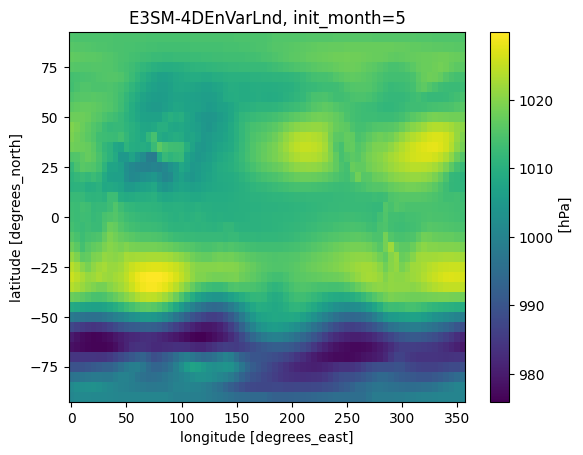

In [38]:
for case_key, by_month in e3sm_da_by_case_month.items():
    for init_month, da in by_month.items():
        da.isel(Y=0, L=0, M=0).plot()
        plt.title(f"{case_key}, init_month={init_month}")
        plt.show()



### Get Observational datasets
- Load observational datasets from the E3SM Diags archive (CMOR variables).
- Harmonize in time, variable naming, and space (regridding to a common grid).
- Provide consistent reference fields for hindcast evaluation.
- Compute OBS seasonal averages as a simple rolling mean
- Regrid to analysis grid 

In [39]:
%%time
# Load observations using the selected field configuration.
obs_dir = WORKFLOW_SETTINGS["obs"]["data_dir"]
obs_name = cfg["obs_name"]
obs_var = cfg["obs_var"]
obs_map = {field: obs_var}
obs_ys = cfg["obs_ys"]
obs_ye = cfg["obs_ye"]
verbose = WORKFLOW_SETTINGS["obs"]["verbose"]
obs_chunks = dict(WORKFLOW_SETTINGS["obs"]["chunks"])

# Resolve the source identity without opening observations on a cached restart.
obs_path_pattern = cfg["obs_path_pattern"]
obs_source_files = (
    obs_access.resolve_glob_files(obs_path_pattern)
    if source_identity_mode == "inventory" else []
)
# Shared with the teleconnection workflow, so either can reuse the other's cache.
observation_data_identity = observation_source_identity(
    archive_root=obs_dir, product=obs_name, variable=obs_var,
    years=(obs_ys, obs_ye), path_pattern=obs_path_pattern,
    mode=source_identity_mode,
    configured_revision=WORKFLOW_SETTINGS["obs"]["source_revision"],
    snapshot_dir=_snapshot_dir, paths=obs_source_files,
)
expected_obs_attrs = {
    "cache_kind": "unmasked_prepared_observations_v1",
    "observation_data_identity": observation_data_identity,
    "variable": field, "target_grid": target_grid_identity,
    "regridding_method": regrid_method,
    "unit_conversion_version": UNIT_CONVERSION_VERSION,
}
# Fixed name: provenance lives in the attributes checked below, so a stale
# cache is rebuilt in place rather than written under a new name.
obs_cache_path = leadtime_acc_dir(
    "observations", "prepared_skill", analysis_component, field,
    f"{obs_name}_{field}_seasonal_{grid_token(target_grid_identity)}_"
    f"{units_token(UNIT_CONVERSION_VERSION)}.nc",
    root=S2D_DIAG_ROOT,
)
obs_cache_ok, obs_cache_reason = cache_status(
    obs_cache_path, expected_attrs=expected_obs_attrs,
    required_variables=("observation",),
)
if source_identity_mode == "snapshot" and not obs_cache_ok:
    raise RuntimeError(
        f"Required observation cache is unavailable: {obs_cache_path}: {obs_cache_reason}. "
        "Run once in inventory mode with archive access."
    )
if obs_cache_ok and (source_identity_mode == "snapshot" or not seasonal_force_rewrite):
    print(f"Loading prepared observations: {obs_cache_path}")
else:
    obs_monthly = obs_access.get_monthly_data_from_pattern(
        path_pattern=obs_path_pattern,
        field=obs_var,
        start_year=obs_ys,
        end_year=obs_ye,
        chunks=obs_chunks,
        verbose=verbose,
    )
    workflow_resources.track(obs_monthly)

    # Compute OBS seasonal averages.
    obs_seas = obs_access.mon_to_seas_obs(
        obs_monthly,
        var=obs_var,
        field_map=obs_map,
    )

    # Rechunk after rolling.
    obs_seas = obs_seas.chunk(obs_chunks)

    # Build regridder from Dataset, not DataArray.
    regridder_obs = regrid.make_regridder(
        obs_monthly,
        destgrid,
        method=regrid_method,
        periodic=regrid_periodic,
    )

    # Regrid seasonal DataArray.
    try:
        obs_seas_rg = regridder_obs(
            obs_seas,
            output_chunks=obs_chunks,
        )
    except TypeError:
        obs_seas_rg = regridder_obs(obs_seas)

    # Rechunk after regrid and apply variable-specific unit conversion.
    obs_seas_rg = obs_seas_rg.chunk(obs_chunks)
    print(obs_seas_rg)

    obs_seas_rg = cfg["obs_convert"](obs_seas_rg)

    obs_cache = obs_seas_rg.rename("observation").to_dataset()
    obs_cache.attrs.update(expected_obs_attrs)
    atomic_to_netcdf(obs_cache, obs_cache_path, **netcdf_write_options)

obs_prepared = xr.open_dataset(obs_cache_path, chunks=obs_chunks)
workflow_resources.track(obs_prepared)
obs_seas_rg = obs_prepared["observation"]
print(obs_seas_rg)



Loading prepared observations: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/observations/leadtime_acc/prepared_skill/atm/PSL/ERA5_PSL_seasonal_5x5deg_skill_v1.nc
<xarray.DataArray 'observation' (time: 490, lat: 37, lon: 72)> Size: 5MB
dask.array<open_dataset-observation, shape=(490, 37, 72), dtype=float32, chunksize=(24, 37, 72), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 4kB 1979-02-15 00:00:00 ... 2019-11-15 00:00:00
  * lat      (lat) float64 296B -90.0 -85.0 -80.0 -75.0 ... 75.0 80.0 85.0 90.0
  * lon      (lon) float64 576B 0.0 5.0 10.0 15.0 ... 340.0 345.0 350.0 355.0
Attributes:
    regrid_method:  conservative
    units:          hPa
CPU times: user 56.8 ms, sys: 19 ms, total: 75.8 ms
Wall time: 213 ms


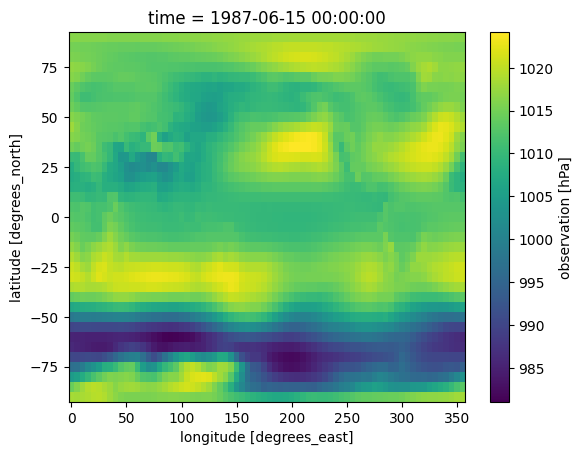

In [40]:
obs_seas_rg.isel(time=min(100, obs_seas_rg.sizes["time"] - 1)).plot()


# Skill Analysis

In [41]:
%%time
time_by_case_month = {
    case_key: {
        init_month: e3sm_seas_by_case_month[case_key][init_month].time.load()
        for init_month in e3sm_months_to_prepare[case_key]
    }
    for case_key in E3SM_CASES
}

# Backward-compatible convenience variables for exploratory cells.
time_by_month = time_by_case_month.get(E3SM_REFERENCE_CASE, {})
e3smle05_time = time_by_month.get(5)
e3smle11_time = time_by_month.get(11)



CPU times: user 24.4 ms, sys: 9.25 ms, total: 33.6 ms
Wall time: 216 ms


In [42]:
%%time
# Load or create versioned, analysis-ready E3SM anomaly bundles.
import functools

prepared_reuse = prepared_mode != "rebuild"
prepared_skill_datasets = []
anom_by_case_month = {}
clim_by_case_month = {}

for case_key, case_info in E3SM_CASES.items():
    anom_by_case_month[case_key] = {}
    clim_by_case_month[case_key] = {}

    for init_month in CASE_INIT_MONTHS[case_key]:
        prepared_source = case_info["cache_tag"]
        prepared_path, expected_attrs = prepared_specs_by_case_month[case_key][init_month]

        prepared = leadtime_realm_skill.prepare_drift_removed_anomaly(
            lambda ck=case_key, im=init_month: e3sm_da_by_case_month[ck][im],
            lambda ck=case_key, im=init_month: time_by_case_month[ck][im],
            prepared_path=prepared_path,
            expected_attrs=expected_attrs,
            source=prepared_source,
            component=analysis_component,
            field=field,
            init_month=init_month,
            climatology_years=(climy0, climy1),
            requested_years=INIT_YEARS_BY_CASE_MONTH[case_key][init_month],
            prepared_chunks=prepared_chunks,
            reuse=prepared_reuse,
            force_recompute=prepared_force_recompute,
        )

        prepared_skill_datasets.append(prepared)
        workflow_resources.track(prepared)
        anomaly = prepared["anomaly"]
        anom_by_case_month[case_key][init_month] = anomaly
        clim_by_case_month[case_key][init_month] = prepared["climatology"]
        time_by_case_month[case_key][init_month] = prepared["time"].load()

# Backward-compatible convenience variables for exploratory cells.
anom_by_month = anom_by_case_month[E3SM_REFERENCE_CASE]
clim_by_month = clim_by_case_month[E3SM_REFERENCE_CASE]
e3smle05_anom = anom_by_month.get(5)
e3smle11_anom = anom_by_month.get(11)
e3smle05_clim = clim_by_month.get(5)
e3smle11_clim = clim_by_month.get(11)


def common_e3sm_years(init_month):
    """Initialization years shared by every E3SM case covering init_month."""
    return functools.reduce(np.intersect1d, (
        by_month[init_month].Y.values
        for by_month in anom_by_case_month.values() if init_month in by_month
    ))

Loading prepared input: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/JRA55_FOSIRL/leadtime_acc/prepared_skill/atm/PSL/JRA55_FOSIRL_init05_PSL_seasonal_anomaly_y1980-1995_ny16_clim_1980_1995_m10_l8_5x5deg_skill_v1.nc


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "Y" starting at index 3. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "L" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "M" starting at index 2. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))


Loading prepared input: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/Reanalysis/leadtime_acc/prepared_skill/atm/PSL/Reanalysis_init05_PSL_seasonal_anomaly_y1980-1995_ny16_clim_1980_1995_m10_l8_5x5deg_skill_v1.nc


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "Y" starting at index 3. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "L" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "M" starting at index 2. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))


Loading prepared input: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarOcn/leadtime_acc/prepared_skill/atm/PSL/4DEnVarOcn_init05_PSL_seasonal_anomaly_y1980-1995_ny16_clim_1980_1995_m10_l8_5x5deg_skill_v1.nc
Creating prepared input: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarLnd/leadtime_acc/prepared_skill/atm/PSL/4DEnVarLnd_init05_PSL_seasonal_anomaly_y1980-1989_ny10_clim_1980_1995_m10_l8_5x5deg_skill_v1.nc


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "Y" starting at index 3. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "L" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "M" starting at index 2. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))


CPU times: user 1.01 s, sys: 377 ms, total: 1.38 s
Wall time: 5.39 s


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "Y" starting at index 3. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "L" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "M" starting at index 2. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))


In [43]:
%%time
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping CESM-SMYLE anomaly preparation: no CESM-SMYLE benchmark is configured for field={field!r}.")
    smyle_time_by_month = {}
    smyle_anom_by_month = {}
    smyle_clim_by_month = {}
    smyle05_time = smyle11_time = None
    smyle05_anom = smyle11_anom = None
    smyle05_clim = smyle11_clim = None
else:
    # Load or create versioned, analysis-ready CESM-SMYLE anomaly bundles.
    smyle_time_by_month = {
        init_month: smyle_seas_by_month[init_month].time.load()
        for init_month in smyle_months_to_prepare
    }

    smyle_anom_by_month = {}
    smyle_clim_by_month = {}

    for init_month in init_months:
        prepared_path, expected_attrs = smyle_prepared_specs_by_month[init_month]

        prepared = leadtime_realm_skill.prepare_drift_removed_anomaly(
            lambda im=init_month: smyle_da_by_month[im],
            lambda im=init_month: smyle_time_by_month[im],
            prepared_path=prepared_path,
            expected_attrs=expected_attrs,
            source="CESM-SMYLE",
            component=analysis_component,
            field=field,
            init_month=init_month,
            climatology_years=(climy0, climy1),
            requested_years=INIT_YEARS_BY_MONTH[init_month],
            prepared_chunks=prepared_chunks,
            reuse=prepared_reuse,
            force_recompute=prepared_force_recompute,
        )

        prepared_skill_datasets.append(prepared)
        workflow_resources.track(prepared)
        anomaly = prepared["anomaly"]
        smyle_anom_by_month[init_month] = anomaly
        smyle_clim_by_month[init_month] = prepared["climatology"]
        smyle_time_by_month[init_month] = prepared["time"].load()

    smyle05_time = smyle_time_by_month.get(5)
    smyle11_time = smyle_time_by_month.get(11)
    smyle05_anom = smyle_anom_by_month.get(5)
    smyle11_anom = smyle_anom_by_month.get(11)
    smyle05_clim = smyle_clim_by_month.get(5)
    smyle11_clim = smyle_clim_by_month.get(11)

# Apply the common domain only after all unmasked prepared bundles are open.
# Its actual values and coordinates enter downstream cache provenance.
analysis_domain_identity = "all_surface_v1"
if cfg.get("ocean_only", False):
    samples = [
        anom_by_case_month[case_key][month].isel(Y=0, M=0, L=0, drop=True).notnull()
        for case_key in E3SM_CASES for month in CASE_INIT_MONTHS[case_key]
    ]
    ocean_mask = leadtime_realm_skill.common_finite_ocean_mask(samples)
    analysis_domain_identity = ocean_mask_identity(ocean_mask)
    obs_seas_rg = obs_seas_rg.where(ocean_mask)
    for case_key in E3SM_CASES:
        for month in CASE_INIT_MONTHS[case_key]:
            anom_by_case_month[case_key][month] = anom_by_case_month[case_key][month].where(ocean_mask)
    for month in init_months:
        smyle_anom_by_month[month] = smyle_anom_by_month[month].where(ocean_mask)
    print(f"Common ocean domain retains {int(ocean_mask.sum())}/{ocean_mask.size} cells")

# Refresh aliases after applying the analysis domain.
anom_by_month = anom_by_case_month[E3SM_REFERENCE_CASE]
e3smle05_anom, e3smle11_anom = anom_by_month.get(5), anom_by_month.get(11)
smyle05_anom, smyle11_anom = smyle_anom_by_month.get(5), smyle_anom_by_month.get(11)

# Backward-compatible aliases for older exploratory cells.
if cfg["obs_name"] == "ERA5":
    obs_era5_seas_rg = obs_seas_rg
if field == "PRECT":
    obs_gpcp_seas_rg = obs_seas_rg

Loading prepared input: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/CESM-SMYLE/leadtime_acc/prepared_skill/atm/PSL/CESM-SMYLE_init05_PSL_seasonal_anomaly_y1980-1995_ny16_clim_1980_1995_m20_l8_5x5deg_skill_v1.nc
CPU times: user 114 ms, sys: 50.9 ms, total: 165 ms
Wall time: 352 ms


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "Y" starting at index 3. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "L" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_prepared_cache.py:356: UserWarning: The specified chunks separate the stored chunks along dimension "M" starting at index 2. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_dataset(path, chunks=dict(chunks or {}))


In [44]:
# Optional lightweight sanity check for drift removal.
# The full anomaly arrays are large, so this cell is disabled by default.

if WORKFLOW_SETTINGS["diagnostics"].get("run_drift_check", False):
    drift_check_sample = WORKFLOW_SETTINGS["diagnostics"].get("drift_check_sample", {})
    for case_key in E3SM_CASES:
        for init_month in CASE_INIT_MONTHS[case_key]:
            if init_month not in e3sm_da_by_case_month.get(case_key, {}):
                print(
                    f"Skipping independent drift check for cached {case_key}, month {init_month:02d}; "
                    "use prepared_skill.mode='rebuild' to check against source data."
                )
                continue
            diagnostic_data = e3sm_da_by_case_month[case_key][init_month]
            diagnostic_clim = clim_by_case_month[case_key][init_month]
            if cfg.get("ocean_only", False):
                diagnostic_data = diagnostic_data.where(ocean_mask)
                diagnostic_clim = diagnostic_clim.where(ocean_mask)
            check_remove_drift_sample(
                diagnostic_data,
                time_by_case_month[case_key][init_month],
                anom_by_case_month[case_key][init_month],
                diagnostic_clim,
                climy0,
                climy1,
                drift_check_sample,
                f"{case_key}, init_month={init_month}",
            )
else:
    print("Skipping optional drift-removal diagnostic; set WORKFLOW_SETTINGS['diagnostics']['run_drift_check'] = True to run a sampled check.")


Skipping optional drift-removal diagnostic; set WORKFLOW_SETTINGS['diagnostics']['run_drift_check'] = True to run a sampled check.


In [45]:
%%time
# Compute and save E3SM skill data separately for each case/init month.
# Files are stored under <case>/leadtime_acc/skill/<component>/<field>/.
e3smle_skill_dir = None

# False reuses existing skill NetCDF files; set True only for intentional regeneration.
force_compute = WORKFLOW_SETTINGS["skill"]["force_compute"]
detrend = WORKFLOW_SETTINGS["skill"]["detrend"]
skill_chunk_model = dict(WORKFLOW_SETTINGS["skill"]["model_chunks"])
skill_chunk_obs = dict(WORKFLOW_SETTINGS["skill"]["obs_chunks"])
skill_lead_start = WORKFLOW_SETTINGS["skill"]["lead_start"]
skill_lead_end = WORKFLOW_SETTINGS["skill"]["lead_end"]

clim_start = cftime.DatetimeNoLeap(climy0, 1, 1)
clim_end = cftime.DatetimeNoLeap(climy1, 12, 31)
skill_required_variables = leadtime_realm_skill.ACC_SKILL_REQUIRED_VARIABLES

# Include the applied analysis domain in every downstream result identity.
skill_observation_identity = source_fingerprint(
    {"observation_data_identity": observation_data_identity,
     "analysis_domain_identity": analysis_domain_identity},
    source_revision="leadtime_acc_domain_v1",
)
skill_cache_common = {
    "variable": field,
    "climatology_years": (climy0, climy1),
    "observation_product": obs_name,
    "observation_variable": obs_var,
    "observation_data_identity": skill_observation_identity,
    "target_grid": target_grid_identity,
    "regridding_method": regrid_method,
    "lead_start": skill_lead_start,
    "lead_end": skill_lead_end,
    "detrend": detrend,
    "unit_conversion_version": UNIT_CONVERSION_VERSION,
}

skill_by_case_month = {}
obs_skill = obs_seas_rg.chunk(skill_chunk_obs)

for case_key, case_info in E3SM_CASES.items():
    cache_tag = case_info["cache_tag"]
    skill_dir = e3sm_leadtime_dir(case_info, "skill", field)
    skill_dir.mkdir(parents=True, exist_ok=True)
    skill_by_case_month[case_key] = {}

    for init_month in CASE_INIT_MONTHS[case_key]:
        verification_years = anom_by_case_month[case_key][init_month].Y.values
        year_token = verification_year_token(verification_years)
        prepared_expected = prepared_specs_by_case_month[case_key][init_month][1]
        expected_skill_attrs = expected_skill_cache_attrs(
            source=cache_tag, case_prefix=case_info["case_prefix"],
            source_data_identity=prepared_expected["source_data_identity"],
            init_month=init_month, verification_years=verification_years,
            ensemble_member_count=anom_by_case_month[case_key][init_month].sizes["M"],
            **skill_cache_common,
        )
        if detrend:
            outname = f"{cache_tag}_init{init_month:02d}_{field}_skill_{year_token}_clim_{climy0}_{climy1}_l{skill_lead_start}-{skill_lead_end}_detrend.nc"
        else:
            outname = f"{cache_tag}_init{init_month:02d}_{field}_skill_{year_token}_clim_{climy0}_{climy1}_l{skill_lead_start}-{skill_lead_end}.nc"

        outfile = skill_dir / outname

        model_anom = anom_by_case_month[case_key][init_month].chunk(skill_chunk_model)
        model_time = time_by_case_month[case_key][init_month]

        skill_ds = leadtime_realm_skill.compute_and_cache_skill(
            model_anom, model_time, obs_skill, clim_start, clim_end,
            skill_lead_start, skill_lead_end,
            outfile=outfile, expected_attrs=expected_skill_attrs,
            netcdf_write_options=netcdf_write_options,
            detrend=detrend, force_compute=force_compute,
            required_variables=skill_required_variables,
        )

        skill_by_case_month[case_key][init_month] = skill_ds

        print(outfile)
        print(skill_ds)

# Backward-compatible aliases.
skill_by_month = skill_by_case_month[E3SM_REFERENCE_CASE]
skill05_ds = skill_by_month.get(5)
skill11_ds = skill_by_month.get(11)

/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/JRA55_FOSIRL/leadtime_acc/skill/atm/PSL/JRA55_FOSIRL_init05_PSL_skill_y1980-1995_ny16_clim_1980_1995_l1-8_detrend.nc
<xarray.Dataset> Size: 2MB
Dimensions:             (L: 8, lat: 37, lon: 72)
Coordinates:
  * L                   (L) int64 64B 3 6 9 12 15 18 21 24
  * lat                 (lat) float64 296B -90.0 -85.0 -80.0 ... 80.0 85.0 90.0
  * lon                 (lon) float64 576B 0.0 5.0 10.0 ... 345.0 350.0 355.0
Data variables: (12/13)
    corr                (L, lat, lon) float64 170kB 0.1537 0.1534 ... nan nan
    pval                (L, lat, lon) float64 170kB 0.5845 0.5851 ... nan nan
    rmse                (L, lat, lon) float64 170kB 1.06 1.06 1.057 ... nan nan
    msss                (L, lat, lon) float64 170kB -0.1236 -0.1229 ... nan nan
    rpc                 (L, lat, lon) float64 170kB 0.3228 0.3199 ... nan nan
    sig_obs             (L, lat, lon) float64 170kB 3.56 3.582 ... 4.408 4.441
    ...                 

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarLnd/leadtime_acc/skill/atm/PSL/4DEnVarLnd_init05_PSL_skill_y1980-1989_ny10_clim_1980_1995_l1-8_detrend.nc
<xarray.Dataset> Size: 2MB
Dimensions:             (lat: 37, lon: 72, L: 8)
Coordinates:
  * lat                 (lat) float64 296B -90.0 -85.0 -80.0 ... 80.0 85.0 90.0
  * lon                 (lon) float64 576B 0.0 5.0 10.0 ... 345.0 350.0 355.0
  * L                   (L) int64 64B 3 6 9 12 15 18 21 24
Data variables: (12/13)
    corr                (L, lat, lon) float64 170kB -0.101 -0.09492 ... nan nan
    pval                (L, lat, lon) float64 170kB 0.7812 0.8081 ... nan nan
    rmse                (L, lat, lon) float64 170kB 1.121 1.119 ... nan nan
    msss                (L, lat, lon) float64 170kB -0.2566 -0.2519 ... nan nan
    rpc                 (L, lat, lon) float64 170kB nan nan nan ... nan nan nan
    sig_obs             (L, lat, lon) float64 170kB 2.988 2.974 ... 4.485 4.516
    ...                  ..

In [46]:
%%time
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping the CESM-SMYLE benchmark skill computation: no CESM-SMYLE benchmark is configured for field={field!r}.")
    smyle_skill_by_month = {}
    smyle_overlap_skill_by_month = {}
    smyle05_skill_ds = smyle11_skill_ds = None
    skill_delta_by_case_month = {case_key: {} for case_key in E3SM_CASES}
    skill_delta_by_month = {}
else:
    # Compute and save CESM-SMYLE benchmark skill with the same observations/settings.
    # Files are stored under CESM-SMYLE/leadtime_acc/skill/<component>/<field>/.
    smyle_skill_outdir = smyle_leadtime_dir("skill", field)
    os.makedirs(smyle_skill_outdir, exist_ok=True)

    smyle_skill_by_month = {}
    smyle_overlap_skill_by_month = {}
    obs_skill = obs_skill.chunk(skill_chunk_obs)

    for init_month in init_months:
        # Initialization months can have different valid-year coordinates.
        # Build the overlap independently for each month so every selected Y
        # value exists in the anomaly and time arrays and in every E3SM case
        # covering that month.
        common_years = np.intersect1d(
            smyle_anom_by_month[init_month].Y.values,
            smyle_time_by_month[init_month].Y.values,
        )
        common_years = np.intersect1d(common_years, common_e3sm_years(init_month))
        full_years = smyle_anom_by_month[init_month].Y.values
        full_year_token = verification_year_token(full_years)
        overlap_year_token = verification_year_token(common_years)
        smyle_prepared_expected = smyle_prepared_specs_by_month[init_month][1]
        expected_full_attrs = expected_skill_cache_attrs(
            source="CESM-SMYLE", case_prefix=smyle_prepared_expected["case_prefix"],
            source_data_identity=smyle_prepared_expected["source_data_identity"],
            init_month=init_month, verification_years=full_years,
            ensemble_member_count=smyle_anom_by_month[init_month].sizes["M"],
            cache_kind="skill_full_record", **skill_cache_common,
        )
        expected_overlap_attrs = expected_skill_cache_attrs(
            source="CESM-SMYLE", case_prefix=smyle_prepared_expected["case_prefix"],
            source_data_identity=smyle_prepared_expected["source_data_identity"],
            init_month=init_month, verification_years=common_years,
            ensemble_member_count=smyle_anom_by_month[init_month].sizes["M"],
            cache_kind="skill_e3sm_overlap", **skill_cache_common,
        )

        if detrend:
            outname = f"CESM-SMYLE_init{init_month:02d}_{field}_skill_{full_year_token}_clim_{climy0}_{climy1}_l{skill_lead_start}-{skill_lead_end}_detrend.nc"
            outname_overlap = f"CESM-SMYLE_init{init_month:02d}_{field}_skill_{overlap_year_token}_clim_{climy0}_{climy1}_l{skill_lead_start}-{skill_lead_end}_overlap_detrend.nc"
        else:
            outname = f"CESM-SMYLE_init{init_month:02d}_{field}_skill_{full_year_token}_clim_{climy0}_{climy1}_l{skill_lead_start}-{skill_lead_end}.nc"
            outname_overlap = f"CESM-SMYLE_init{init_month:02d}_{field}_skill_{overlap_year_token}_clim_{climy0}_{climy1}_l{skill_lead_start}-{skill_lead_end}_overlap.nc"

        outfile = os.path.join(smyle_skill_outdir, outname)
        outfile_overlap = os.path.join(smyle_skill_outdir, outname_overlap)

        # 1. Full 50-year CESM-SMYLE skill
        model_anom = smyle_anom_by_month[init_month].chunk(skill_chunk_model)
        model_time = smyle_time_by_month[init_month]

        skill_ds = leadtime_realm_skill.compute_and_cache_skill(
            model_anom, model_time, obs_skill, clim_start, clim_end,
            skill_lead_start, skill_lead_end,
            outfile=outfile, expected_attrs=expected_full_attrs,
            netcdf_write_options=netcdf_write_options,
            detrend=detrend, force_compute=force_compute,
            required_variables=skill_required_variables,
        )

        smyle_skill_by_month[init_month] = skill_ds

        # 2. Common overlap years (39-year) CESM-SMYLE skill
        model_anom_ov = smyle_anom_by_month[init_month].sel(Y=common_years).chunk(skill_chunk_model)
        model_time_ov = smyle_time_by_month[init_month].sel(Y=common_years)

        skill_ds_overlap = leadtime_realm_skill.compute_and_cache_skill(
            model_anom_ov, model_time_ov, obs_skill, clim_start, clim_end,
            skill_lead_start, skill_lead_end,
            outfile=outfile_overlap, expected_attrs=expected_overlap_attrs,
            netcdf_write_options=netcdf_write_options,
            detrend=detrend, force_compute=force_compute,
            required_variables=skill_required_variables,
        )

        smyle_overlap_skill_by_month[init_month] = skill_ds_overlap

    smyle05_skill_ds = smyle_skill_by_month.get(5)
    smyle11_skill_ds = smyle_skill_by_month.get(11)

    skill_delta_by_case_month = {
        case_key: {
            init_month: skill_by_case_month[case_key][init_month].corr - smyle_overlap_skill_by_month[init_month].corr
            for init_month in CASE_INIT_MONTHS[case_key]
        }
        for case_key in E3SM_CASES
    }

    skill_delta_by_month = skill_delta_by_case_month[E3SM_REFERENCE_CASE]

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


CPU times: user 3.65 s, sys: 966 ms, total: 4.62 s
Wall time: 11.8 s


### Final ACC Plot: BSMYLE vs E3SMLE (Common Overlap Years)
- Uses the common verification years derived independently for every initialization month and E3SM case.
- Plots each initialization month as paired columns: CESM-SMYLE on the left, E3SMLE on the right.
- Shows the full ACC field; black dots mark grid cells where ACC is significant against the observations (p < 0.1), and each panel reports the significant-area percentage in its lower-left corner.



In [47]:
# Read saved CESM-SMYLE and multi-case E3SM skill data and plot side by side.
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from matplotlib.offsetbox import AnchoredText

from esp_lab.utils import mapplot_utils as maps
from esp_lab.utils import mov_utils as mov
from esp_lab.utils.filename_utils import figure_filename

def lead_label(init_month, lead):
    return f"{lead:2d}: {seasonal_label(init_month, lead)}"


def add_lead_label(ax, text):
    label = AnchoredText(
        text,
        loc=lead_label_loc,
        prop=dict(size=lead_label_size, weight=fweight, family="monospace"),
        frameon=True,
        pad=lead_label_pad,
        borderpad=lead_label_borderpad,
    )
    label.patch.set(**lead_label_bbox)
    ax.add_artist(label)


def set_map_axis_linewidth(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(map_axis_linewidth)
    if hasattr(ax, "outline_patch"):
        ax.outline_patch.set_linewidth(map_axis_linewidth)


def add_lat_lon_labels(ax, row, col, nrows, ncols):
    # Keep labels on the outer edges so the multi-panel plot stays readable.
    set_map_axis_linewidth(ax)
    ax.set_xticks(lon_ticks, crs=projection)
    ax.set_yticks(lat_ticks, crs=projection)
    ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax.yaxis.set_major_formatter(LatitudeFormatter())
    ax.tick_params(
        labelsize=lat_lon_label_size,
        length=lat_lon_tick_length,
        width=lat_lon_tick_width,
        top=False,
        right=False,
        labelbottom=(row == nrows - 1),
        labelleft=(col == 0),
    )
    ax.gridlines(
        crs=projection,
        linewidth=gridline_width,
        color=gridline_color,
        alpha=gridline_alpha,
        linestyle=gridline_style,
        draw_labels=False,
    )

# ---------------------------------------------------------------------------
# User-adjustable final-plot setup
# ---------------------------------------------------------------------------
metric = "ACC"

model_order = ["CESM-SMYLE"] + list(E3SM_CASES)
model_display_name = {"CESM-SMYLE": "CESM-SMYLE"}
model_display_name.update({
    case_key: case_info.get("display_name", case_key)
    for case_key, case_info in E3SM_CASES.items()
})
# Seasonal lead denotes the first monthly lead in each 3-month window:
# lead 1 = months 1-3, lead 4 = months 4-6, etc.
max_plot_leads = WORKFLOW_SETTINGS["final_acc_figures"]["max_leads"]
init_month_names = {
    1: "JAN", 2: "FEB", 3: "MAR", 4: "APR", 5: "MAY", 6: "JUN",
    7: "JUL", 8: "AUG", 9: "SEP", 10: "OCT", 11: "NOV", 12: "DEC",
}

sigon = True
siglvl = 0.1
mask_negacc = False

# Single font-size control for the full multi-panel figure.
fontz = 20
panel_title_size = fontz
lead_label_size = fontz * 0.85
lat_lon_label_size = fontz * 0.8
colorbar_label_size = fontz
colorbar_tick_size = fontz * 0.85
suptitle_size = fontz * 1.15
fweight = 'bold'

# Plot style/layout controls.
figfmt = "png"
plot_diag_cfg = WORKFLOW_SETTINGS.get("diagnostics", {})
fig_col_width = 5.0
fig_row_height = 3.0
projection = ccrs.PlateCarree()
suptitle_y = 0.995
tight_layout_rect = [0, 0.16, 1, 0.985]
bottom = 0.10
wspace = 0.05
save_bbox = "tight"

cmap = "blue2red_acc"
coff = 0.5
ci = 0.1
cmin = -1
cmax = 1

colorbar_axes = [0.25, 0.055, 0.5, 0.02]
colorbar_orientation = 'horizontal'
dpi = plot_diag_cfg.get("pre_significance_acc_dpi", 150)
show_figure_inline = plot_diag_cfg.get("show_pre_significance_acc_plot", False)

lon_ticks = [-160, -80, 0, 80, 160]
lat_ticks = [-60, -30, 0, 30, 60]
lat_lon_tick_length = 2.5
lat_lon_tick_width = 0.5
map_axis_linewidth = 1.0
gridline_width = 0.35
gridline_color = "0.35"
gridline_alpha = 0.35
gridline_style = "-"

lead_label_loc = "lower right"
lead_label_pad = 0.25
lead_label_borderpad = 0.35
lead_label_bbox = dict(facecolor=(1, 1, 1, 0.72), edgecolor='black', linewidth=0.3, boxstyle='round,pad=0.1')



In [48]:
%%time
make_pre_significance_acc_plot = WORKFLOW_SETTINGS.get("diagnostics", {}).get(
    "make_pre_significance_acc_plot",
    False,
)

make_pre_significance_acc_plot = make_pre_significance_acc_plot and cfg.get("has_smyle_benchmark", True)

if not make_pre_significance_acc_plot:
    print(
        "Skipping pre-significance ACC overview plot; set "
        "WORKFLOW_SETTINGS['diagnostics']['make_pre_significance_acc_plot'] = True to run it."
    )
else:
    # This plot cell intentionally consumes the single field/configuration selected
    # in the variable-driven setup cell above. Do not silently fall back to another
    # field here; that can mix cached products from different diagnostics.
    _required_setup_names = [
        "field",
        "cfg",
        "init_months",
        "climy0",
        "climy1",
        "detrend",
        "E3SM_CASES",
        "E3SM_REFERENCE_CASE",
        "smyle_overlap_skill_by_month",
        "skill_by_case_month",
    ]
    _missing_setup_names = [name for name in _required_setup_names if name not in globals()]
    if _missing_setup_names:
        raise RuntimeError(
            "Run the variable-driven setup cell before this final ACC plotting cell; "
            f"missing: {_missing_setup_names}"
        )
    FIGURE_OUTDIR.mkdir(parents=True, exist_ok=True)

    skill_by_model = {model: {} for model in model_order}

    for init_month in init_months:
        skill_by_model["CESM-SMYLE"][init_month] = smyle_overlap_skill_by_month[init_month]
        for case_key in E3SM_CASES:
            if init_month in skill_by_case_month[case_key]:
                skill_by_model[case_key][init_month] = skill_by_case_month[case_key][init_month]

    # Keep the old variable names available for exploratory cells below/above.
    skill_by_case_month = {
        case_key: skill_by_model[case_key]
        for case_key in E3SM_CASES
    }
    skill_by_month = skill_by_model[E3SM_REFERENCE_CASE]

    skill_plot_by_model = {
        model: {
            init_month: ds.assign_coords(L=ds.L - 2)
            for init_month, ds in by_month.items()
        }
        for model, by_month in skill_by_model.items()
    }

    # One column per (month, model); models without that month are omitted.
    overview_columns = [
        (init_month, model) for init_month in init_months for model in model_order
        if init_month in skill_plot_by_model[model]
    ]
    if not overview_columns:
        raise RuntimeError("No initialization months are available for the overview")
    first_month, first_model = overview_columns[0]
    plot_leads = [
        lead for lead in skill_plot_by_model[first_model][first_month].L.values
        if all(
            lead in skill_plot_by_model[model][init_month].L.values
            for init_month, model in overview_columns
        )
    ]

    plot_leads = plot_leads[:max_plot_leads]
    if not plot_leads:
        raise RuntimeError("No common leads are available for the overview")
    nrows = len(plot_leads)
    ncols = len(overview_columns)

    subtitle = build_plot_subtitle(cfg["plot_name"], WORKFLOW_SETTINGS, detrend)
    if detrend:
        trendstr = "wt_detrend"
    else:
        trendstr = "wo_detrend"

    corr_by_model = {model: {} for model in model_order}
    for init_month, model in overview_columns:
        skill_plot = skill_plot_by_model[model][init_month]
        # Full ACC field; cells with significant ACC (p < siglvl) are
        # dotted on the map below instead of being blanked out.
        corr = skill_plot.corr
        sigstr = "wt_sigmarker" if sigon else "wo_sigmarker"

        if mask_negacc:
            corr = corr.where(corr >= 0)

        corr_by_model[model][init_month] = corr

    print("=== Sanity check: data range ===")
    for model in model_order:
        for init_month, corr in corr_by_model[model].items():
            print(
                f"{model} init_month={init_month} corr min/max:",
                float(corr.min(skipna=True)),
                float(corr.max(skipna=True)),
            )

    _markers = WORKFLOW_SETTINGS["final_acc_figures"]["markers"]
    SIG_MARKER_STYLE = {
        "latlim": _markers["latlim"],
        "marker_stride": _markers["marker_stride"],
        "marker_size": _markers["filled_marker_size"],
        "marker_color": _markers["marker_color"],
        "annotate_percentage": True,
    }
    figname = FIGURE_FILENAMES["acc"]

    print(f"working on figure: {figname}")

    fig = plt.figure(figsize=(fig_col_width * ncols, fig_row_height * nrows))
    fig.suptitle(subtitle, fontsize=suptitle_size, fontweight=fweight, y=suptitle_y)
    proj = projection
    cntr = None

    for i, lead in enumerate(plot_leads):
        for col, (init_month, model) in enumerate(overview_columns):
            skill_plot = skill_plot_by_model[model][init_month]
            subplot = i * ncols + col + 1
            model_name = model_display_name.get(model, model)
            title = (
                f"{model_name} ({init_month_names.get(init_month, f'{init_month:02d}')})"
                if i == 0 else ''
            )
            ax, cntr = maps.map_pcolor_global_subplot(
                fig,
                corr_by_model[model][init_month].sel(L=lead),
                skill_plot.lon,
                skill_plot.lat,
                ci, cmin, cmax,
                title,
                nrows, ncols, subplot,
                proj, cmap=cmap, cutoff=coff,
                fontsize=panel_title_size,
            )
            add_lead_label(ax, lead_label(init_month, lead))
            if sigon:
                longitude_2d, latitude_2d = np.meshgrid(skill_plot.lon, skill_plot.lat)
                add_pointwise_significance_markers(
                    ax, skill_plot, int(np.flatnonzero(skill_plot.L.values == lead)[0]),
                    longitude_2d=longitude_2d, latitude_2d=latitude_2d,
                    significance_level=siglvl, style=SIG_MARKER_STYLE,
                    font_size=panel_title_size * 0.7,
                    label_bbox=_markers["label_bbox"], label_position="lower left",
                )
            add_lat_lon_labels(ax, i, col, nrows, ncols)

    fig.tight_layout(rect=tight_layout_rect)
    fig.subplots_adjust(bottom=bottom, wspace=wspace)
    cbar_ax = fig.add_axes(colorbar_axes)
    cbar = fig.colorbar(cntr, cax=cbar_ax, orientation=colorbar_orientation)
    cbar.set_label(metric, fontsize=colorbar_label_size, fontweight=fweight)
    cbar.ax.tick_params(labelsize=colorbar_tick_size)

    figpath = FIGURE_OUTDIR / figname
    mov.save_figure(
        fig, figpath,
        mode="",
        metric="leadtime_acc",
        title=f"Leadtime ACC Skill: {field}",
        caption=(f"ACC skill vs lead month; dots mark ACC significant at p < {siglvl} "
                 "with the significant-area percentage in each panel."),
        dpi=dpi,
    )
    print("Saved figure:", figpath)
    if show_figure_inline:
        plt.show()
    else:
        plt.close(fig)


=== Sanity check: data range ===
CESM-SMYLE init_month=5 corr min/max: -0.9024387674982747 0.9571023959856249
E3SM-FOSIRL init_month=5 corr min/max: -0.817477285148891 0.8715398155574149
E3SM-Reanalysis init_month=5 corr min/max: -0.7997749943285266 0.8900657369417017
E3SM-4DEnVarOcn init_month=5 corr min/max: -0.7985249995104111 0.8165249931173231
E3SM-4DEnVarLnd init_month=5 corr min/max: -0.9332777273497855 0.9474847590270717
working on figure: fig_atm_acc_psl_acc.png
Saved figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/fig_atm_acc_psl_acc.png
CPU times: user 11.7 s, sys: 2.25 s, total: 14 s
Wall time: 13.6 s


### Test significance of CESM-SMYLE vs E3SMLE, accounting for finite ensemble size
- Uses the common verification years for both systems.
- Set `E3SM_COMPARE_CASE_SELECTION` to one case, a list of cases, or `"all"`.
- Following the Yeager et al. method, resamples the larger ensemble down to the size of the smaller ensemble. Here CESM-SMYLE has 20 members and E3SMLE has 10, so CESM-SMYLE is repeatedly sampled at 10 members without replacement.
- Compares the resulting CESM-SMYLE ACC distribution with the full 10-member E3SMLE ACC.


In [49]:
%%time
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping the CESM-SMYLE vs E3SM significance comparison: no CESM-SMYLE benchmark is configured for field={field!r}.")
else:
    # CESM-SMYLE vs each E3SM hindcast ACC significance figure.
    #
    # Scientific purpose:
    # 1. Restrict CESM-SMYLE and E3SM to common verification years.
    # 2. Resample the larger CESM-SMYLE ensemble to the E3SM ensemble size.
    # 3. Repeat the CESM-SMYLE subsampling N times without replacement.
    # 4. Compute accpval = fraction of resampled CESM-SMYLE ACC > fixed E3SM ACC.

    compare_cfg = WORKFLOW_SETTINGS["finite_ensemble_compare"]
    compare_mode = compare_cfg["mode"]
    compare_force_recompute = compare_cfg["force_recompute"]
    compare_detrend = compare_cfg["detrend"]
    compare_random_seed = compare_cfg["random_seed"]
    cache_compare_anomalies = compare_cfg["cache_anomalies"]
    persist_compare_inputs = compare_cfg["persist_inputs"]

    # Select which configured E3SM hindcasts to compare with CESM-SMYLE.
    # Use "all" for every configured case, a string for one case, or a list for many.
    E3SM_COMPARE_CASE_SELECTION = compare_cfg["case_selection"]
    if E3SM_COMPARE_CASE_SELECTION == "all":
        E3SM_COMPARE_CASES = list(E3SM_CASES)
    elif isinstance(E3SM_COMPARE_CASE_SELECTION, str):
        E3SM_COMPARE_CASES = [E3SM_COMPARE_CASE_SELECTION]
    else:
        E3SM_COMPARE_CASES = list(E3SM_COMPARE_CASE_SELECTION)

    missing_compare_cases = [case_key for case_key in E3SM_COMPARE_CASES if case_key not in E3SM_CASES]
    if missing_compare_cases:
        raise ValueError(f"E3SM_COMPARE_CASE_SELECTION includes cases not in E3SM_CASES: {missing_compare_cases}")
    if not E3SM_COMPARE_CASES:
        raise ValueError("E3SM_COMPARE_CASE_SELECTION did not resolve to any E3SM cases.")

    print(f"E3SM comparison cases: {E3SM_COMPARE_CASES}")

    compare_modes = compare_cfg["modes"]
    if compare_mode not in compare_modes:
        raise ValueError(f"compare_mode must be one of {list(compare_modes)}")

    compare_mode_cfg = compare_modes[compare_mode]
    compare_init_months = [m for m in compare_mode_cfg["init_months"] if m in init_months]
    compare_iterations = compare_mode_cfg["iterations"]
    compare_lead_start = compare_mode_cfg["lead_start"]
    compare_lead_end = compare_mode_cfg["lead_end"]

    if not compare_init_months:
        raise ValueError("No requested compare_init_months are available in init_months.")

    # Dedicated chunks for the significance calculation. Do not reuse the
    # earlier skill chunks, which combine all leads into each task.
    compare_chunk_model = dict(WORKFLOW_SETTINGS["finite_ensemble_compare"]["model_chunks"])
    compare_chunk_obs = dict(WORKFLOW_SETTINGS["finite_ensemble_compare"]["obs_chunks"])
    compare_iteration_batch_size = compare_cfg["iteration_batch_size"]

    obs_compare = obs_seas_rg.chunk(compare_chunk_obs)

    case_cache_tags = {
        case_key: case_info.get("cache_tag", case_key.replace("E3SM-", ""))
        for case_key, case_info in E3SM_CASES.items()
    }
    comparison_cache_layout = SkillComparisonCacheLayout(
        root=S2D_DIAG_ROOT, component=analysis_component, variable=field,
        climatology_years=(climy0, climy1), detrend=compare_detrend,
        mode=compare_mode, iterations=compare_iterations,
        random_seed=compare_random_seed,
    )


    smyle_compare_skill_by_case_month = {}
    e3sm_compare_skill_by_case_month = {}
    accpval_by_case_month = {}
    compare_years_by_case_month = {}
    compare_ens_size_by_case_month = {}

    for case_key in E3SM_COMPARE_CASES:
        smyle_compare_skill_by_case_month[case_key] = {}
        e3sm_compare_skill_by_case_month[case_key] = {}
        accpval_by_case_month[case_key] = {}
        compare_years_by_case_month[case_key] = {}
        compare_ens_size_by_case_month[case_key] = {}

        for compare_init_month in compare_init_months:
            if compare_init_month not in anom_by_case_month[case_key]:
                continue
            e3sm_compare_member_count = anom_by_case_month[case_key][compare_init_month].sizes["M"]
            smyle_compare_member_count = smyle_anom_by_month[compare_init_month].sizes["M"]

            if smyle_compare_member_count < e3sm_compare_member_count:
                raise ValueError(
                    "This comparison expects CESM-SMYLE to be the larger ensemble; "
                    f"got SMYLE={smyle_compare_member_count}, {case_key}={e3sm_compare_member_count}."
                )
            compare_ens_size = e3sm_compare_member_count
            compare_ens_size_by_case_month[case_key][compare_init_month] = compare_ens_size

            compare_years = np.intersect1d(
                smyle_anom_by_month[compare_init_month].Y.values,
                anom_by_case_month[case_key][compare_init_month].Y.values,
            )
            compare_years_by_case_month[case_key][compare_init_month] = compare_years
            e3sm_prepared_expected = prepared_specs_by_case_month[case_key][compare_init_month][1]
            smyle_prepared_expected = smyle_prepared_specs_by_month[compare_init_month][1]
            resampling_identity = {
                "field": field,
                "comparison_case": case_key,
                "initialization_month": int(compare_init_month),
                "verification_years": [year_number(year) for year in compare_years],
                "population_member_count": int(smyle_compare_member_count),
                "sample_member_count": int(compare_ens_size),
                "iterations": int(compare_iterations),
                "lead_start": int(compare_lead_start),
                "lead_end": int(compare_lead_end),
                "detrend": bool(compare_detrend),
                "smyle_source_identity": smyle_prepared_expected["source_data_identity"],
                "e3sm_source_identity": e3sm_prepared_expected["source_data_identity"],
            }
            derived_resampling_seed = stable_resampling_seed(
                compare_random_seed, resampling_identity
            )
            generated_member_indices = generate_member_indices(
                population_size=smyle_compare_member_count,
                sample_size=compare_ens_size, iterations=compare_iterations,
                seed=derived_resampling_seed,
            )
            selection_attrs = member_selection_attrs(
                base_seed=compare_random_seed, derived_seed=derived_resampling_seed,
                identity=resampling_identity, member_indices=generated_member_indices,
            )
            selection_attrs["population_member_count"] = int(smyle_compare_member_count)
            comparison_attrs = {
                "comparison_case": case_key,
                "comparison_ensemble_member_count": int(compare_ens_size),
                "resampling_iterations": int(compare_iterations),
                "random_seed": int(compare_random_seed),
                "comparison_mode": compare_mode,
            } | selection_attrs
            comparison_skill_common = dict(
                skill_cache_common, detrend=compare_detrend,
                lead_start=compare_lead_start, lead_end=compare_lead_end,
            )
            expected_e3sm_compare_attrs = expected_skill_cache_attrs(
                source=case_cache_tags[case_key],
                case_prefix=E3SM_CASES[case_key]["case_prefix"],
                source_data_identity=e3sm_prepared_expected["source_data_identity"],
                init_month=compare_init_month, verification_years=compare_years,
                ensemble_member_count=compare_ens_size,
                cache_kind="fixed_ensemble_comparison_skill",
                **comparison_skill_common,
            ) | comparison_attrs
            expected_smyle_compare_attrs = expected_skill_cache_attrs(
                source="CESM-SMYLE",
                case_prefix=smyle_prepared_expected["case_prefix"],
                source_data_identity=smyle_prepared_expected["source_data_identity"],
                init_month=compare_init_month, verification_years=compare_years,
                ensemble_member_count=compare_ens_size,
                cache_kind="resampled_comparison_skill",
                **comparison_skill_common,
            ) | comparison_attrs
            expected_accp_attrs = dict(
                expected_e3sm_compare_attrs, cache_kind="fraction_smyle_gt_e3sm"
            )

            smyle_file, e3sm_file, accp_file = comparison_cache_layout.result_paths(
                case_cache_tags[case_key], compare_init_month, compare_ens_size, compare_years
            )
            member_selection_file = comparison_cache_layout.member_selection_path(smyle_file)
            member_indices_all = load_or_write_member_selection(
                member_selection_file, generated_member_indices, selection_attrs,
                smyle_compare_member_count, force=compare_force_recompute,
                write_options=netcdf_write_options,
            )

            smyle_cache_ok, _ = cache_status(
                smyle_file, expected_attrs=expected_smyle_compare_attrs,
                required_variables=("corr",),
            )
            e3sm_cache_ok, _ = cache_status(
                e3sm_file, expected_attrs=expected_e3sm_compare_attrs,
                required_variables=("corr",),
            )
            accp_cache_ok, _ = cache_status(
                accp_file, expected_attrs=expected_accp_attrs,
                required_variables=("accpval",),
            )
            if (not compare_force_recompute and smyle_cache_ok and e3sm_cache_ok and accp_cache_ok):
                print(f"Loading cached significance results for {case_key}, init_month={compare_init_month}")

                smyle_skill_tmp = load_netcdf(smyle_file)
                e3sm_skill_tmp = load_netcdf(e3sm_file)

                with xr.open_dataset(accp_file) as ds:
                    accpval_tmp = ds["accpval"].load()

                # Older caches encoded an all-missing comparison as 0%. Repair
                # only those invalid cells from the already-cached skill arrays;
                # this does not repeat the expensive resampling calculation.
                valid_comparison = (
                    smyle_skill_tmp.corr.notnull()
                    & e3sm_skill_tmp.corr.notnull()
                ).any("iteration")
                invalid_cached = accpval_tmp.notnull() & ~valid_comparison
                accpval_tmp = accpval_tmp.where(valid_comparison)
                if bool(invalid_cached.any()):
                    print(f"Repairing missing-value mask in {accp_file}")
                    repaired_accp = accpval_tmp.to_dataset(name="accpval")
                    repaired_accp.attrs.update(expected_accp_attrs)
                    atomic_to_netcdf(repaired_accp, accp_file, **netcdf_write_options)

            else:
                print(f"Computing significance results for {case_key}, init_month={compare_init_month}")
                print(f"compare_mode       : {compare_mode}")
                print(f"compare_iterations : {compare_iterations}")
                print(f"compare_leads      : {compare_lead_start} to {compare_lead_end}")
                print(f"compare_detrend    : {compare_detrend}")
                print(f"cache anomalies    : {cache_compare_anomalies}")
                print(f"persist inputs     : {persist_compare_inputs}")

                smyle_compare_anom = (
                    smyle_anom_by_month[compare_init_month]
                    .sel(Y=compare_years)
                    .chunk(compare_chunk_model)
                )

                e3sm_compare_anom = (
                    anom_by_case_month[case_key][compare_init_month]
                    .sel(Y=compare_years)
                    .chunk(compare_chunk_model)
                )

                if cache_compare_anomalies:
                    smyle_anom_file, e3sm_anom_file = comparison_cache_layout.anomaly_paths(
                        case_cache_tags[case_key], compare_init_month, compare_years
                    )

                    smyle_compare_anom = cache_comparison_anomaly(
                        smyle_compare_anom,
                        smyle_anom_file,
                        variable="anom",
                        chunks=compare_chunk_model,
                        force=compare_force_recompute,
                        expected_attrs=dict(
                            expected_smyle_compare_attrs, cache_kind="comparison_anomaly"
                        ),
                        resource_tracker=workflow_resources,
                        write_options=netcdf_write_options,
                    )

                    e3sm_compare_anom = cache_comparison_anomaly(
                        e3sm_compare_anom,
                        e3sm_anom_file,
                        variable="anom",
                        chunks=compare_chunk_model,
                        force=compare_force_recompute,
                        expected_attrs=dict(
                            expected_e3sm_compare_attrs, cache_kind="comparison_anomaly"
                        ),
                        resource_tracker=workflow_resources,
                        write_options=netcdf_write_options,
                    )

                elif persist_compare_inputs:
                    smyle_compare_anom = smyle_compare_anom.persist()
                    e3sm_compare_anom = e3sm_compare_anom.persist()
                    wait([smyle_compare_anom, e3sm_compare_anom])

                smyle_compare_time = smyle_time_by_month[compare_init_month].sel(
                    Y=compare_years
                )

                e3sm_compare_time = time_by_case_month[case_key][compare_init_month].sel(
                    Y=compare_years
                )

                if e3sm_cache_ok and not compare_force_recompute:
                    print(f"Loading cached fixed {case_key} comparison skill...")
                    e3sm_skill_tmp = load_netcdf(e3sm_file)
                else:
                    print(f"Computing fixed {case_key} comparison skill...")
                    e3sm_skill_tmp = compute_skill_lead_range(
                        e3sm_compare_anom,
                        e3sm_compare_time,
                        obs_compare,
                        str(climy0),
                        str(climy1),
                        compare_lead_start,
                        compare_lead_end,
                        resamp=0,
                        detrend=compare_detrend,
                    ).load()
                    e3sm_skill_tmp.attrs.update(expected_e3sm_compare_attrs)
                    atomic_to_netcdf(e3sm_skill_tmp, e3sm_file, **netcdf_write_options)

                print("Computing CESM-SMYLE resampled skill distribution...")

                smyle_skill_batches = []
                for batch_start in range(0, compare_iterations, compare_iteration_batch_size):
                    batch_stop = min(batch_start + compare_iteration_batch_size, compare_iterations)
                    batch_file = comparison_cache_layout.batch_path(
                        smyle_file, batch_start, batch_stop
                    )
                    expected_batch_attrs = dict(
                        expected_smyle_compare_attrs,
                        cache_kind="resampled_comparison_skill_batch",
                        iteration_batch_start=int(batch_start),
                        iteration_batch_stop=int(batch_stop),
                    )
                    batch_cache_ok, _ = cache_status(
                        batch_file, expected_attrs=expected_batch_attrs,
                        required_variables=("corr",),
                    )
                    if batch_cache_ok and not compare_force_recompute:
                        print(f"  loading iterations {batch_start + 1}-{batch_stop}")
                        batch_skill = load_netcdf(batch_file)
                    else:
                        print(f"  computing iterations {batch_start + 1}-{batch_stop}")
                        batch_skill = compute_skill_lead_range_batch(
                            smyle_compare_anom,
                            smyle_compare_time,
                            obs_compare,
                            str(climy0),
                            str(climy1),
                            member_indices_all[batch_start:batch_stop],
                            compare_lead_start,
                            compare_lead_end,
                            detrend=compare_detrend,
                            metrics=("corr",),
                        ).load()
                        batch_skill = batch_skill.assign_coords(
                            iteration=np.arange(batch_start, batch_stop)
                        )
                        batch_skill.attrs.update(expected_batch_attrs)
                        atomic_to_netcdf(batch_skill, batch_file, **netcdf_write_options)
                    smyle_skill_batches.append(batch_skill)

                smyle_skill_tmp = xr.concat(smyle_skill_batches, dim="iteration")

                print("Computing ACC superiority fraction...")

                accpval_tmp = acc_superiority_fraction(
                    smyle_skill_tmp.corr, e3sm_skill_tmp.corr
                ).rename("accpval").load()

                print(f"Writing significance cache for {case_key}, init_month={compare_init_month}")

                smyle_skill_tmp.attrs.update(expected_smyle_compare_attrs)
                accpval_ds = accpval_tmp.to_dataset(name="accpval")
                accpval_ds.attrs.update(expected_accp_attrs)
                atomic_to_netcdf(smyle_skill_tmp, smyle_file, **netcdf_write_options)
                atomic_to_netcdf(accpval_ds, accp_file, **netcdf_write_options)

            smyle_compare_skill_by_case_month[case_key][compare_init_month] = smyle_skill_tmp
            e3sm_compare_skill_by_case_month[case_key][compare_init_month] = e3sm_skill_tmp
            accpval_by_case_month[case_key][compare_init_month] = accpval_tmp

            print("")
            print("case_key:", case_key)
            print("compare_init_month:", compare_init_month)
            print(
                "compare_years:",
                year_number(compare_years[0]),
                year_number(compare_years[-1]),
                "n=",
                compare_years.size,
            )
            print(f"{case_key} members:", e3sm_compare_member_count)
            print("CESM-SMYLE members:", smyle_compare_member_count)
            print("resampled ensemble size:", compare_ens_size)
            print(f"{case_key} fixed-ensemble skill:")
            print(e3sm_skill_tmp)
            print("CESM-SMYLE resampled skill distribution:")
            print(smyle_compare_skill_by_case_month[case_key][compare_init_month])


    # Backward-compatible aliases for downstream plotting.
    # Prefer the reference case and November if available; otherwise use the
    # first compared case with results and its last processed month.
    if not any(accpval_by_case_month.values()):
        raise ValueError("No selected E3SM case covers the comparison init months.")
    compare_case = next(
        case_key for case_key in dict.fromkeys([E3SM_REFERENCE_CASE, *E3SM_COMPARE_CASES])
        if case_key in E3SM_COMPARE_CASES and accpval_by_case_month[case_key]
    )
    compare_case_months = list(accpval_by_case_month[compare_case])
    if 11 in compare_case_months:
        compare_init_month = 11
    else:
        compare_init_month = compare_case_months[-1]
    compare_years = compare_years_by_case_month[compare_case][compare_init_month]
    smyle_compare_skill_by_month = smyle_compare_skill_by_case_month[compare_case]
    e3sm_compare_skill_by_month = e3sm_compare_skill_by_case_month[compare_case]
    accpval_by_month = accpval_by_case_month[compare_case]
    compare_ens_size_by_month = compare_ens_size_by_case_month[compare_case]
    compare_years_by_month = compare_years_by_case_month[compare_case]

    smyle_compare_skill = smyle_compare_skill_by_month[compare_init_month]
    e3sm_compare_skill = e3sm_compare_skill_by_month[compare_init_month]
    accpval = accpval_by_month[compare_init_month]

    lon2d, lat2d = np.meshgrid(destgrid.lon, destgrid.lat)



E3SM comparison cases: ['E3SM-FOSIRL', 'E3SM-Reanalysis', 'E3SM-4DEnVarOcn', 'E3SM-4DEnVarLnd']
Loading deterministic member selections: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/CESM-SMYLE/leadtime_acc/resampling_cache/atm/member_selections/PSL/CESM-SMYLE_init05_PSL_clim_1980_1995_resamp_to_JRA55_FOSIRL_skill_detrend_final_n10_iter100_seed42_1980-1995_ny16_member_indices.nc
Loading cached significance results for E3SM-FOSIRL, init_month=5

case_key: E3SM-FOSIRL
compare_init_month: 5
compare_years: 1980 1995 n= 16
E3SM-FOSIRL members: 10
CESM-SMYLE members: 20
resampled ensemble size: 10
E3SM-FOSIRL fixed-ensemble skill:
<xarray.Dataset> Size: 2MB
Dimensions:             (L: 8, lat: 37, lon: 72)
Coordinates:
  * L                   (L) int64 64B 3 6 9 12 15 18 21 24
  * lat                 (lat) float64 296B -90.0 -85.0 -80.0 ... 80.0 85.0 90.0
  * lon                 (lon) float64 576B 0.0 5.0 10.0 ... 345.0 350.0 355.0
Data variables: (12/13)
    corr                (L,

/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_skill_cache.py:402: UserWarning: The specified chunks separate the stored chunks along dimension "L" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  dataset = resource_tracker.track(xr.open_dataset(path, chunks=chunks))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_skill_cache.py:402: UserWarning: The specified chunks separate the stored chunks along dimension "lat" starting at index 30. This could degrade performance. Instead, consider rechunking after loading.
  dataset = resource_tracker.track(xr.open_dataset(path, chunks=chunks))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_skill_cache.py:402: UserWarning: The specified chunks separate the stored chunks along dimension "lon" starting at index 60. This could degrade performance. Instead, consider rechunking after loading.
  dataset = resource_tracker.track(xr.open_dataset(path, chunks=chunks))


Opening cached anomaly with Dask chunks: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarLnd/leadtime_acc/comparison/atm/anomalies/PSL/4DEnVarLnd_init05_PSL_clim_1980_1995_compare_anom_detrend_1980-1989_ny10.nc
Computing fixed E3SM-4DEnVarLnd comparison skill...


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_skill_cache.py:402: UserWarning: The specified chunks separate the stored chunks along dimension "L" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  dataset = resource_tracker.track(xr.open_dataset(path, chunks=chunks))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_skill_cache.py:402: UserWarning: The specified chunks separate the stored chunks along dimension "lat" starting at index 30. This could degrade performance. Instead, consider rechunking after loading.
  dataset = resource_tracker.track(xr.open_dataset(path, chunks=chunks))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/leadtime_skill_cache.py:402: UserWarning: The specified chunks separate the stored chunks along dimension "lon" starting at index 60. This could degrade performance. Instead, consider rechunking after loading.
  dataset = resource_tracker.track(xr.open_dataset(path, chunks=chunks))
/global/homes/z/zhan391/.con

Computing CESM-SMYLE resampled skill distribution...
  computing iterations 1-10
  computing iterations 11-20
  computing iterations 21-30


  computing iterations 31-40
  computing iterations 41-50
  computing iterations 51-60
  computing iterations 61-70
  computing iterations 71-80
  computing iterations 81-90
  computing iterations 91-100
Computing ACC superiority fraction...
Writing significance cache for E3SM-4DEnVarLnd, init_month=5

case_key: E3SM-4DEnVarLnd
compare_init_month: 5
compare_years: 1980 1989 n= 10
E3SM-4DEnVarLnd members: 10
CESM-SMYLE members: 20
resampled ensemble size: 10
E3SM-4DEnVarLnd fixed-ensemble skill:
<xarray.Dataset> Size: 2MB
Dimensions:             (lat: 37, lon: 72, L: 8)
Coordinates:
  * lat                 (lat) float64 296B -90.0 -85.0 -80.0 ... 80.0 85.0 90.0
  * lon                 (lon) float64 576B 0.0 5.0 10.0 ... 345.0 350.0 355.0
  * L                   (L) int64 64B 3 6 9 12 15 18 21 24
Data variables: (12/13)
    corr                (L, lat, lon) float64 170kB -0.101 -0.09492 ... nan nan
    pval                (L, lat, lon) float64 170kB 0.7812 0.8081 ... nan nan
    rmse    

In [50]:
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping the CESM-SMYLE comparison figure setup: no CESM-SMYLE benchmark is configured for field={field!r}.")
else:
    # -----------------------------------------------------------------------------
    # Final ACC comparison figure setup
    # -----------------------------------------------------------------------------
    # Values come from WORKFLOW_SETTINGS["final_acc_figures"].
    init_month_names = {
        1: "JAN", 2: "FEB", 3: "MAR", 4: "APR", 5: "MAY", 6: "JUN",
        7: "JUL", 8: "AUG", 9: "SEP", 10: "OCT", 11: "NOV", 12: "DEC",
    }

    final_acc_cfg = WORKFLOW_SETTINGS["final_acc_figures"]
    final_geom_cfg = final_acc_cfg["geometry"]
    final_marker_cfg = final_acc_cfg["markers"]
    final_acc_style_cfg = final_acc_cfg["acc"]
    final_skilldiff_style_cfg = final_acc_cfg["skilldiff"]

    compare_init_months_requested = list(final_acc_cfg["init_months"])
    compare_plot_max_leads = final_acc_cfg["max_leads"]

    # Panel geometry and spacing
    compare_fig_col_width = final_geom_cfg["fig_col_width"]
    compare_fig_row_height = final_geom_cfg["fig_row_height"]
    compare_section_gap = final_geom_cfg["section_gap"]
    compare_section_gap_fig_width = final_geom_cfg["section_gap_fig_width"]
    compare_tight_layout_rect = list(final_geom_cfg["tight_layout_rect"])
    compare_subplots_top = final_geom_cfg["subplots_top"]
    compare_subplots_bottom = final_geom_cfg["subplots_bottom"]
    compare_subplots_hspace = final_geom_cfg["subplots_hspace"]
    compare_subplots_wspace = final_geom_cfg["subplots_wspace"]
    compare_month_header_y = final_geom_cfg["month_header_y"]
    compare_divider_y0 = final_geom_cfg["divider_y0"]
    compare_divider_y1 = final_geom_cfg["divider_y1"]
    compare_divider_color = final_geom_cfg["divider_color"]
    compare_divider_linewidth = final_geom_cfg["divider_linewidth"]
    compare_cbar_rect = list(final_geom_cfg["cbar_rect"])

    # Shared map and significance-marker settings
    compare_label_bbox = dict(final_marker_cfg["label_bbox"])

    # ACC figure contents and styling
    acc_include_cesm_smyle = final_acc_style_cfg["include_cesm_smyle"]
    acc_cesm_label = final_acc_style_cfg["cesm_label"]
    acc_ci = final_acc_style_cfg["ci"]
    acc_cmin = final_acc_style_cfg["cmin"]
    acc_cmax = final_acc_style_cfg["cmax"]
    acc_cmap = final_acc_style_cfg["cmap"]
    acc_cutoff = final_acc_style_cfg["cutoff"]
    acc_fontz = final_acc_style_cfg["fontz"]
    acc_panel_title_size = acc_fontz * 1.2
    acc_lead_label_size = acc_fontz * 0.85
    acc_lat_lon_label_size = acc_fontz * 0.8
    acc_suptitle_size = acc_fontz * 1.25
    acc_colorbar_label_size = acc_fontz
    acc_colorbar_tick_size = acc_fontz * 0.85
    acc_section_label_size = acc_fontz * 1.05

    # E3SM minus matched CESM-SMYLE ACC figure styling
    skilldiff_ci = final_skilldiff_style_cfg["ci"]
    skilldiff_cmin = final_skilldiff_style_cfg["cmin"]
    skilldiff_cmax = final_skilldiff_style_cfg["cmax"]
    skilldiff_cmap = final_skilldiff_style_cfg["cmap"]
    skilldiff_cutoff = final_skilldiff_style_cfg["cutoff"]
    skilldiff_fontz = final_skilldiff_style_cfg["fontz"]
    skilldiff_panel_title_size = skilldiff_fontz
    skilldiff_lat_lon_label_size = skilldiff_fontz * 0.95
    skilldiff_suptitle_size = skilldiff_fontz * 0.95
    skilldiff_colorbar_label_size = skilldiff_fontz * 0.95
    skilldiff_colorbar_tick_size = skilldiff_fontz * 0.90
    skilldiff_lead_label_size = skilldiff_fontz * 0.90
    skilldiff_section_label_size = skilldiff_fontz * 1.00

    compare_fweight = final_acc_cfg["font_weight"]

    # Distinguish figures from different lead ranges and resampling configurations.
    comparison_figure_token = source_fingerprint(
        {"cases": E3SM_COMPARE_CASES, "months": compare_init_months,
         "lead_start": compare_lead_start, "lead_end": compare_lead_end,
         "iterations": compare_iterations, "seed": compare_random_seed,
         "domain": analysis_domain_identity}, source_revision="acc_figures_v2",
    ).split(":")[-1][:12]

    # Figure titles and save metadata
    if detrend != compare_detrend:
        raise ValueError("skill.detrend and finite_ensemble_compare.detrend must match")
    trend_label = "linear-detrend" if compare_detrend else "no-detrend"
    initialization_label = ", ".join(
        init_month_names.get(month, f"{month:02d}") for month in compare_init_months_requested
    )
    figure_run_context = (
        f"Verification {lead_years[0]}–{lead_years[-1]}; "
        f"initialization {initialization_label}; climatology {climy0}–{climy1}; "
        f"{trend_label}."
    )
    acc_figure_title = final_acc_style_cfg["title_template"].format(
        plot_name=cfg["plot_name"], field=field, trend_label=trend_label,
    )
    acc_save_title = acc_figure_title
    acc_save_caption = f"{final_acc_style_cfg['caption']} {figure_run_context}"
    skilldiff_figure_title = final_skilldiff_style_cfg["title_template"].format(
        plot_name=cfg["plot_name"], field=field, trend_label=trend_label,
    )
    skilldiff_save_title = final_skilldiff_style_cfg["save_title_template"].format(plot_name=cfg["plot_name"], field=field)
    skilldiff_save_caption = f"{final_skilldiff_style_cfg['caption']} {figure_run_context}"


Saved figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/fig_atm_acc_psl_acc_compare.png


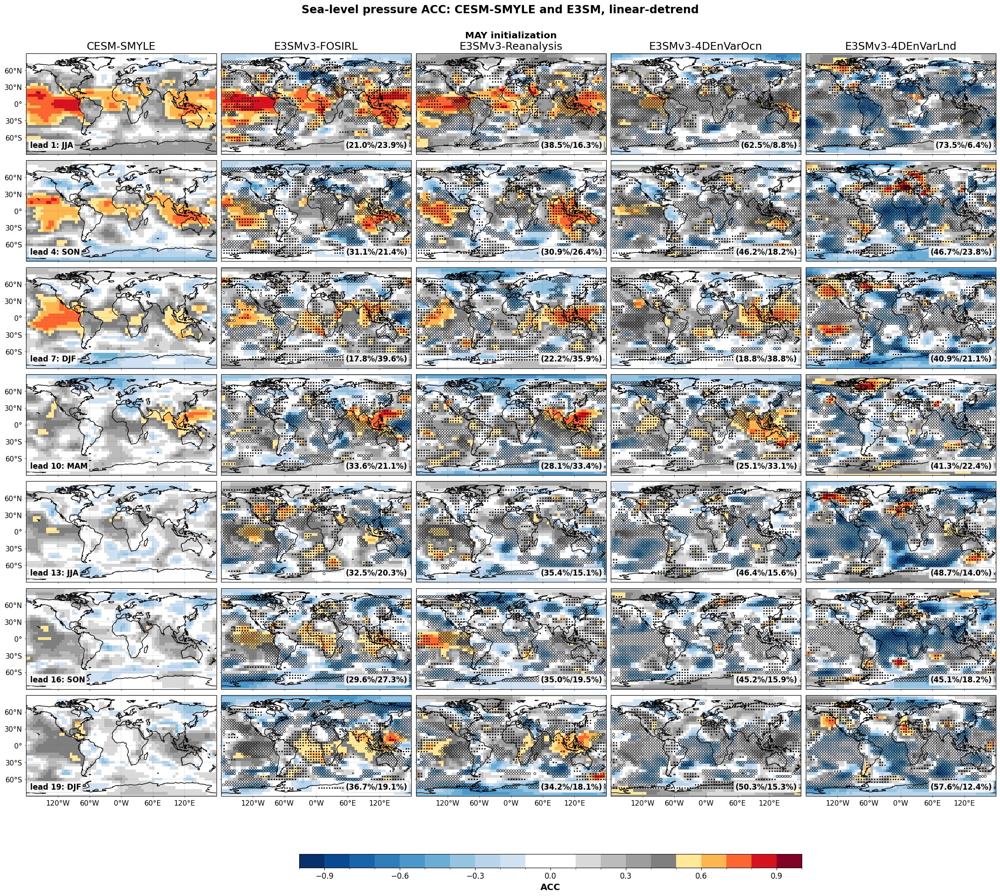

CPU times: user 13.5 s, sys: 2.24 s, total: 15.7 s
Wall time: 15 s


In [51]:
%%time
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping the CESM-SMYLE comparison ACC figure: no CESM-SMYLE benchmark is configured for field={field!r}.")
else:
    # Plot each selected E3SM hindcast ACC with ensemble-size-matched CESM-SMYLE
    # significance markers. The figure columns are grouped by initialization month;
    # selected E3SM cases are shown side by side within each month group.
    ci = acc_ci
    cmin = acc_cmin
    cmax = acc_cmax
    compare_panel_title_size = acc_panel_title_size
    compare_lead_label_size = acc_lead_label_size
    compare_lat_lon_label_size = acc_lat_lon_label_size
    compare_suptitle_size = acc_suptitle_size
    compare_colorbar_label_size = acc_colorbar_label_size
    compare_colorbar_tick_size = acc_colorbar_tick_size
    compare_section_label_size = acc_section_label_size

    compare_init_months_plot = [
        m for m in compare_init_months_requested
        if m in compare_init_months
        and any(m in by_month for by_month in smyle_compare_skill_by_case_month.values())
    ]
    if not compare_init_months_plot:
        raise RuntimeError("None of the requested initialization months are available for plotting.")

    area = destgrid.area
    proj = ccrs.PlateCarree()

    column_specs = []
    for init_month in compare_init_months_plot:
        if acc_include_cesm_smyle and init_month in smyle_skill_by_month:
            column_specs.append((init_month, "CESM-SMYLE", None))

        for case_key in E3SM_COMPARE_CASES:
            if (
                init_month in smyle_compare_skill_by_case_month.get(case_key, {})
                and init_month in e3sm_compare_skill_by_case_month.get(case_key, {})
                and init_month in accpval_by_case_month.get(case_key, {})
            ):
                column_specs.append((init_month, "E3SM", case_key))

    if not column_specs:
        raise RuntimeError("No CESM-SMYLE or E3SM case/month combinations are available for plotting.")


    def _acc_skill_for_column(init_month, model_kind, case_key):
        if model_kind == "CESM-SMYLE":
            leads = next(
                by_month[init_month] for by_month in e3sm_compare_skill_by_case_month.values()
                if init_month in by_month
            ).L
            return smyle_skill_by_month[init_month].sel(L=leads)
        return e3sm_compare_skill_by_case_month[case_key][init_month]


    plot_nlead = min(
        compare_plot_max_leads,
        *(
            _acc_skill_for_column(init_month, model_kind, case_key).sizes["L"]
            for init_month, model_kind, case_key in column_specs
        ),
    )
    nrows = plot_nlead
    ncols = len(column_specs)
    column_months = list(dict.fromkeys(spec[0] for spec in column_specs))
    n_section_gaps = len(column_months) - 1
    section_gap = compare_section_gap if n_section_gaps else 0.0
    fig = plt.figure(figsize=(compare_fig_col_width * ncols + compare_section_gap_fig_width * n_section_gaps, compare_fig_row_height * nrows))
    cntr = None


    for i in range(plot_nlead):
        for col, (compare_init_month, model_kind, case_key) in enumerate(column_specs):
            if model_kind == "CESM-SMYLE":
                case_label = acc_cesm_label
                plot_skill = _acc_skill_for_column(compare_init_month, model_kind, case_key)
                accp = None
            else:
                case_label = E3SM_CASES[case_key].get("display_name", case_key)
                plot_skill = e3sm_compare_skill_by_case_month[case_key][compare_init_month]
                accp = accpval_by_case_month[case_key][compare_init_month]

            init_label = init_month_names.get(compare_init_month, f"{compare_init_month:02d}")
            lead = int(plot_skill.L.values[i])
            display_lead = lead - 2
            leadstr = f"lead {display_lead}: {seasonal_label(compare_init_month, display_lead)}"
            title = f"{case_label}" if i == 0 else ""
            subplot = i * ncols + col + 1

            ax, cntr = maps.map_pcolor_global_subplot(
                fig,
                plot_skill.corr.isel(L=i),
                plot_skill.lon,
                plot_skill.lat,
                ci, cmin, cmax,
                title,
                nrows, ncols, subplot,
                proj, cmap=acc_cmap, cutoff=acc_cutoff,
                fontsize=compare_panel_title_size,
            )
            style_global_map_axis(
                ax, row=i, column=col, nrows=nrows,
                label_size=compare_lat_lon_label_size, style=final_marker_cfg,
            )
            if col == 0 or column_specs[col - 1][0] != compare_init_month:
                ax.text(
                    0.02, 0.05, leadstr,
                    fontsize=compare_lead_label_size,
                    fontweight=compare_fweight,
                    bbox=compare_label_bbox,
                    zorder=10,
                    transform=ax.transAxes,
                    ha="left", va="bottom",
                )
            if accp is not None:
                add_acc_comparison_markers(
                    ax, plot_skill, accp, i, area=area, latitude=destgrid.lat,
                    longitude_2d=lon2d, latitude_2d=lat2d, style=final_marker_cfg,
                    font_size=compare_lead_label_size, font_weight=compare_fweight,
                    label_bbox=compare_label_bbox,
                )

    fig.suptitle(
        acc_figure_title,
        fontsize=compare_suptitle_size,
        fontweight=compare_fweight,
        y=0.995,
    )
    layout_rect = compare_tight_layout_rect.copy()
    layout_rect[2] = layout_rect[2] - section_gap * n_section_gaps
    fig.tight_layout(rect=layout_rect)
    fig.subplots_adjust(top=compare_subplots_top, bottom=compare_subplots_bottom, hspace=compare_subplots_hspace, wspace=compare_subplots_wspace)

    # Shift each later month group right by one section gap per preceding group.
    for col, spec in enumerate(column_specs):
        group_index = column_months.index(spec[0])
        for row in range(nrows if group_index else 0):
            ax = fig.axes[row * ncols + col]
            pos = ax.get_position()
            ax.set_position([pos.x0 + group_index * section_gap, pos.y0, pos.width, pos.height])

    # Add initialization-month headers above their case columns.
    for init_month in compare_init_months_plot:
        cols = [i for i, (m, _, __) in enumerate(column_specs) if m == init_month]
        if not cols:
            continue
        left = min(fig.axes[i].get_position().x0 for i in cols)
        right = max(fig.axes[i].get_position().x1 for i in cols)
        init_label = init_month_names.get(init_month, f"{init_month:02d}")
        fig.text(
            (left + right) / 2,
            compare_month_header_y,
            f"{init_label} initialization",
            ha="center", va="bottom",
            fontsize=compare_section_label_size,
            fontweight=compare_fweight,
        )

    for left_month, right_month in zip(column_months, column_months[1:]):
        left_cols = [i for i, spec in enumerate(column_specs) if spec[0] == left_month]
        right_cols = [i for i, spec in enumerate(column_specs) if spec[0] == right_month]
        divider_x = (
            max(fig.axes[i].get_position().x1 for i in left_cols)
            + min(fig.axes[i].get_position().x0 for i in right_cols)
        ) / 2
        fig.add_artist(plt.Line2D([divider_x, divider_x], [compare_divider_y0, compare_divider_y1], transform=fig.transFigure, color=compare_divider_color, linewidth=compare_divider_linewidth))

    cbar_ax = fig.add_axes(compare_cbar_rect)
    cbar = fig.colorbar(cntr, cax=cbar_ax, orientation="horizontal")
    cbar.set_label("ACC", fontsize=compare_colorbar_label_size, fontweight=compare_fweight)
    cbar.ax.tick_params(labelsize=compare_colorbar_tick_size)

    compare_figname = FIGURE_FILENAMES["compare"]
    compare_figpath = FIGURE_OUTDIR / compare_figname
    mov.save_figure(
        fig, compare_figpath,
        mode="",
        metric="leadtime_acc_compare",
        title=acc_save_title,
        caption=acc_save_caption,
        dpi=300,
    )
    print("Saved figure:", compare_figpath)
    plt.show()


### E3SM ACC With Side-by-Side Case Comparison
- Plots one ACC figure for the selected E3SM cases.
- Set `E3SM_COMPARE_CASE_SELECTION` upstream to one case, multiple cases, or `"all"`.
- Columns are grouped by initialization month in `init_months` order; each case appears only for the months it covers.
- E3SM hindcasts are shown side by side within each month group.


Saved figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/fig_atm_acc_psl_acc_difference.png


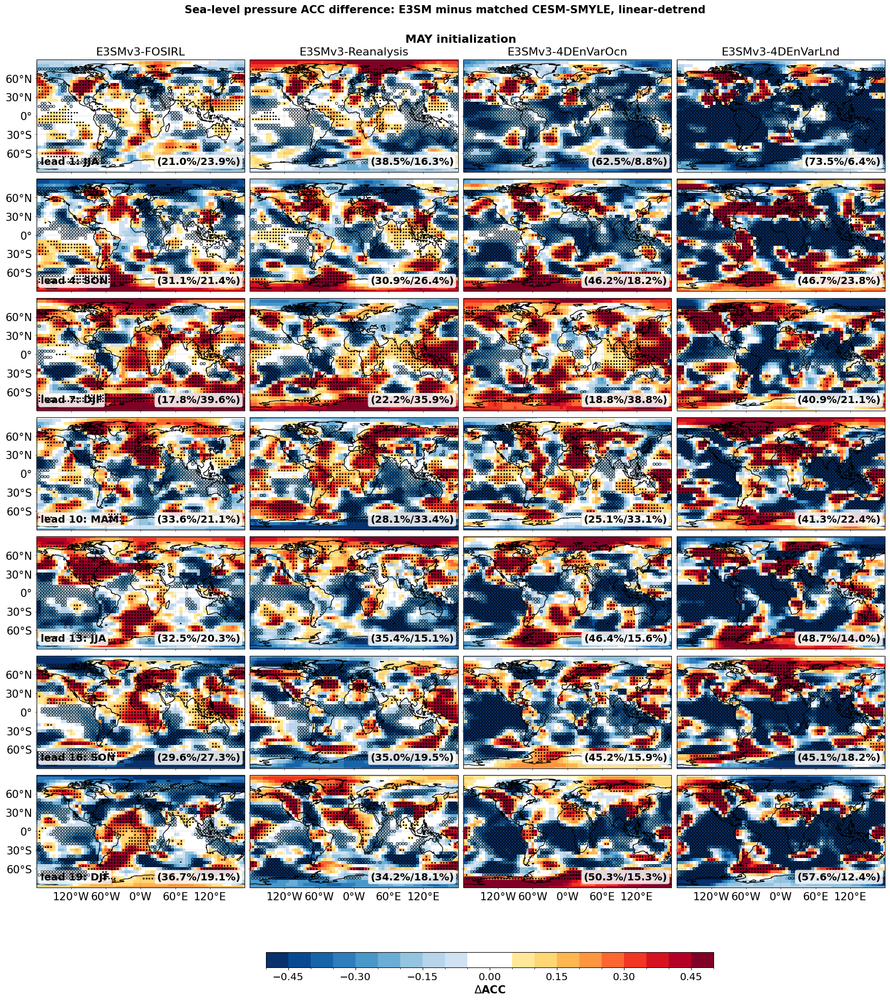

CPU times: user 11.4 s, sys: 2.1 s, total: 13.5 s
Wall time: 12.7 s


In [52]:
%%time
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping the CESM-SMYLE comparison ACC-difference figure: no CESM-SMYLE benchmark is configured for field={field!r}.")
else:
    # Plot fixed 10-member E3SM ACC minus mean matched-size CESM-SMYLE ACC.
    # Columns are grouped by initialization month; selected E3SM cases are shown
    # side by side within each month group.
    ci = skilldiff_ci
    cmin = skilldiff_cmin
    cmax = skilldiff_cmax
    compare_panel_title_size = skilldiff_panel_title_size
    compare_lat_lon_label_size = skilldiff_lat_lon_label_size
    compare_suptitle_size = skilldiff_suptitle_size
    compare_colorbar_label_size = skilldiff_colorbar_label_size
    compare_colorbar_tick_size = skilldiff_colorbar_tick_size
    compare_lead_label_size = skilldiff_lead_label_size
    compare_section_label_size = skilldiff_section_label_size

    compare_init_months_plot = [
        m for m in compare_init_months_requested
        if m in compare_init_months
        and any(m in by_month for by_month in smyle_compare_skill_by_case_month.values())
    ]
    if not compare_init_months_plot:
        raise RuntimeError("None of the requested initialization months are available for plotting.")

    area = destgrid.area
    proj = ccrs.PlateCarree()

    e3sm_compare_skilldiff_by_case_month = {
        case_key: {
            m: e3sm_compare_skill_by_case_month[case_key][m]
            - smyle_compare_skill_by_case_month[case_key][m].mean("iteration")
            for m in compare_init_months_plot
            if m in smyle_compare_skill_by_case_month.get(case_key, {})
            and m in e3sm_compare_skill_by_case_month.get(case_key, {})
        }
        for case_key in E3SM_COMPARE_CASES
    }

    column_specs = []
    for init_month in compare_init_months_plot:
        for case_key in E3SM_COMPARE_CASES:
            if (
                init_month in smyle_compare_skill_by_case_month.get(case_key, {})
                and init_month in e3sm_compare_skill_by_case_month.get(case_key, {})
                and init_month in accpval_by_case_month.get(case_key, {})
                and init_month in e3sm_compare_skilldiff_by_case_month.get(case_key, {})
            ):
                column_specs.append((init_month, case_key))

    if not column_specs:
        raise RuntimeError("No E3SM case/month combinations are available for plotting.")

    plot_nlead = min(
        compare_plot_max_leads,
        *(e3sm_compare_skilldiff_by_case_month[case_key][init_month].sizes["L"] for init_month, case_key in column_specs),
    )
    nrows = plot_nlead
    ncols = len(column_specs)
    column_months = list(dict.fromkeys(spec[0] for spec in column_specs))
    n_section_gaps = len(column_months) - 1
    section_gap = compare_section_gap if n_section_gaps else 0.0
    fig = plt.figure(figsize=(compare_fig_col_width * ncols + compare_section_gap_fig_width * n_section_gaps, compare_fig_row_height * nrows))
    cntr = None


    for i in range(plot_nlead):
        for col, (compare_init_month, case_key) in enumerate(column_specs):
            case_label = E3SM_CASES[case_key].get("display_name", case_key)
            init_label = init_month_names.get(compare_init_month, f"{compare_init_month:02d}")
            smyle_skill = smyle_compare_skill_by_case_month[case_key][compare_init_month]
            skilldiff = e3sm_compare_skilldiff_by_case_month[case_key][compare_init_month]
            accp = accpval_by_case_month[case_key][compare_init_month]
            lead = int(smyle_skill.L.values[i])
            display_lead = lead - 2
            leadstr = f"lead {display_lead}: {seasonal_label(compare_init_month, display_lead)}"
            title = f"{case_label}" if i == 0 else ""
            subplot = i * ncols + col + 1

            ax, cntr = maps.map_pcolor_global_subplot(
                fig,
                skilldiff.corr.isel(L=i),
                smyle_skill.lon,
                smyle_skill.lat,
                ci, cmin, cmax,
                title,
                nrows, ncols, subplot,
                proj, cmap=skilldiff_cmap, cutoff=skilldiff_cutoff,
                fontsize=compare_panel_title_size,
            )
            style_global_map_axis(
                ax, row=i, column=col, nrows=nrows,
                label_size=compare_lat_lon_label_size, style=final_marker_cfg,
            )
            if col == 0 or column_specs[col - 1][0] != compare_init_month:
                ax.text(
                    0.02, 0.05, leadstr,
                    fontsize=compare_lead_label_size,
                    fontweight=compare_fweight,
                    bbox=compare_label_bbox,
                    zorder=10,
                    transform=ax.transAxes,
                    ha="left", va="bottom",
                )
            add_acc_comparison_markers(
                ax, skilldiff, accp, i, area=area, latitude=destgrid.lat,
                longitude_2d=lon2d, latitude_2d=lat2d, style=final_marker_cfg,
                font_size=compare_lead_label_size, font_weight=compare_fweight,
                label_bbox=compare_label_bbox,
            )

    fig.suptitle(
        skilldiff_figure_title,
        fontsize=compare_suptitle_size,
        fontweight=compare_fweight,
        y=0.995,
    )
    layout_rect = compare_tight_layout_rect.copy()
    layout_rect[2] = layout_rect[2] - section_gap * n_section_gaps
    fig.tight_layout(rect=layout_rect)
    fig.subplots_adjust(top=compare_subplots_top, bottom=compare_subplots_bottom, hspace=compare_subplots_hspace, wspace=compare_subplots_wspace)

    # Shift each later month group right by one section gap per preceding group.
    for col, spec in enumerate(column_specs):
        group_index = column_months.index(spec[0])
        for row in range(nrows if group_index else 0):
            ax = fig.axes[row * ncols + col]
            pos = ax.get_position()
            ax.set_position([pos.x0 + group_index * section_gap, pos.y0, pos.width, pos.height])

    # Add initialization-month headers above their case columns.
    for init_month in compare_init_months_plot:
        cols = [i for i, (m, _) in enumerate(column_specs) if m == init_month]
        if not cols:
            continue
        left = min(fig.axes[i].get_position().x0 for i in cols)
        right = max(fig.axes[i].get_position().x1 for i in cols)
        init_label = init_month_names.get(init_month, f"{init_month:02d}")
        fig.text(
            (left + right) / 2,
            compare_month_header_y,
            f"{init_label} initialization",
            ha="center", va="bottom",
            fontsize=compare_section_label_size,
            fontweight=compare_fweight,
        )

    for left_month, right_month in zip(column_months, column_months[1:]):
        left_cols = [i for i, spec in enumerate(column_specs) if spec[0] == left_month]
        right_cols = [i for i, spec in enumerate(column_specs) if spec[0] == right_month]
        divider_x = (
            max(fig.axes[i].get_position().x1 for i in left_cols)
            + min(fig.axes[i].get_position().x0 for i in right_cols)
        ) / 2
        fig.add_artist(plt.Line2D([divider_x, divider_x], [compare_divider_y0, compare_divider_y1], transform=fig.transFigure, color=compare_divider_color, linewidth=compare_divider_linewidth))

    cbar_ax = fig.add_axes(compare_cbar_rect)
    cbar = fig.colorbar(cntr, cax=cbar_ax, orientation="horizontal")
    cbar.set_label(r"${\Delta}$ACC", fontsize=compare_colorbar_label_size, fontweight=compare_fweight)
    cbar.ax.tick_params(labelsize=compare_colorbar_tick_size)

    skilldiff_figname = FIGURE_FILENAMES["difference"]
    skilldiff_figpath = FIGURE_OUTDIR / skilldiff_figname
    mov.save_figure(
        fig, skilldiff_figpath,
        mode="",
        metric="leadtime_acc_diff",
        title=skilldiff_save_title,
        caption=skilldiff_save_caption,
        dpi=300,
    )
    print("Saved figure:", skilldiff_figpath)
    plt.show()

    # Backward-compatible reference-case difference dictionary.
    e3sm_compare_skilldiff_by_month = {
        m: e3sm_compare_skill_by_case_month[compare_case][m]
        - smyle_compare_skill_by_case_month[compare_case][m].mean("iteration")
        for m in compare_init_months_plot
        if m in e3sm_compare_skill_by_case_month[compare_case]
    }


## E3SM ACC differences relative to a selected control

Set `ACC_DIFFERENCE_CONTROL` in the configuration cell to any configured experiment. Each panel shows another experiment minus that control, so positive values indicate higher ACC than the control; the control itself is omitted. No difference-significance stippling is shown because the cached skill files do not contain paired resampling statistics for ACC differences.


In [53]:
%%time
# Shared setup for the E3SM case-difference figure below.
import cartopy.crs as ccrs

from esp_lab.utils import mapplot_utils as maps
from esp_lab.utils import mov_utils as mov

FIGURE_CFG = WORKFLOW_SETTINGS["final_acc_figures"]
FONT_WEIGHT = FIGURE_CFG["font_weight"]
MARKER_CFG = FIGURE_CFG["markers"]
MAP_STYLE = {
    "lon_ticks": [-160, -80, 0, 80, 160],
    "lat_ticks": [-60, -30, 0, 30, 60],
    "tick_length": MARKER_CFG["tick_length"],
    "tick_width": MARKER_CFG["tick_width"],
    "grid_linewidth": MARKER_CFG["grid_linewidth"],
    "grid_color": MARKER_CFG["grid_color"],
    "grid_alpha": MARKER_CFG["grid_alpha"],
}

REFERENCE_DISPLAY_NAME = cfg["obs_name"]
DETREND_DISPLAY_NAME = "linear-detrend" if detrend else "no-detrend"
INIT_MONTH_NAMES = {
    1: "JAN", 2: "FEB", 3: "MAR", 4: "APR", 5: "MAY", 6: "JUN",
    7: "JUL", 8: "AUG", 9: "SEP", 10: "OCT", 11: "NOV", 12: "DEC",
}
case_display_names = {
    case_name: case_cfg.get("display_name", case_name)
    for case_name, case_cfg in E3SM_CASES.items()
}

column_specs = [
    (init_month, case_name)
    for init_month in init_months
    for case_name in E3SM_CASES
    if init_month in skill_by_case_month.get(case_name, {})
]
if not column_specs:
    raise RuntimeError("No E3SM case/month skill is available for plotting")
# Seasonal lead coordinates (3, 6, ...) of the cached skill, capped at max_leads.
FULL_SEASONAL_LEADS = [
    int(lead) for lead in skill_by_case_month[column_specs[0][1]][column_specs[0][0]].L.values
][: FIGURE_CFG["max_leads"]]
if not FULL_SEASONAL_LEADS:
    raise RuntimeError("No seasonal leads are available for plotting")

projection = ccrs.PlateCarree()

CPU times: user 2.11 ms, sys: 0 ns, total: 2.11 ms
Wall time: 2.09 ms


Saved difference figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/fig_atm_acc_psl_acc_case_difference.png


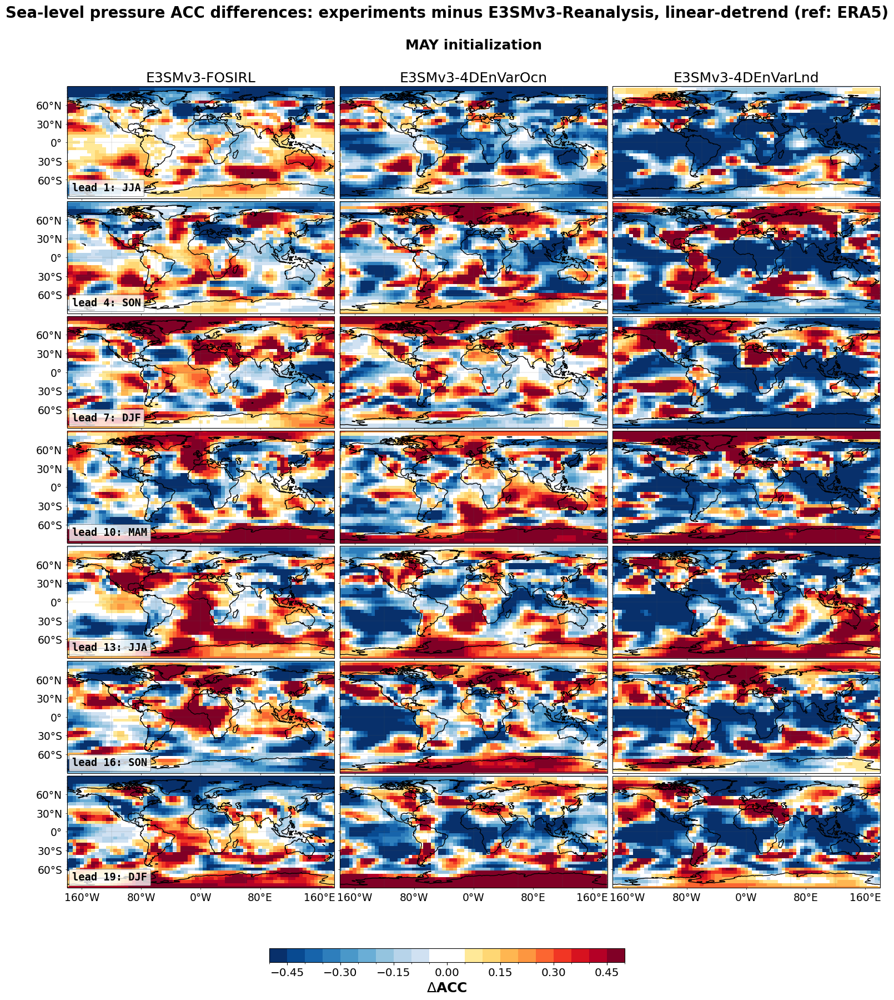

CPU times: user 7.13 s, sys: 1.21 s, total: 8.35 s
Wall time: 8.01 s


In [54]:
%%time
# E3SM ACC differences relative to ACC_DIFFERENCE_CONTROL (1a_lnd style), drawn
# for every field; for fields with CESM-SMYLE it complements the SMYLE Difference figure.
# E3SM ACC differences relative to ACC_DIFFERENCE_CONTROL (1a_lnd style).
# Reuses FIGURE_CFG, MAP_STYLE, column/lead setup, and names from the cell above.
DIFF_PLOT = FIGURE_CFG["case_difference"]
if ACC_DIFFERENCE_CONTROL not in E3SM_CASES:
    raise ValueError(
        f"ACC_DIFFERENCE_CONTROL={ACC_DIFFERENCE_CONTROL!r} is not in E3SM_CASES; "
        f"choose one of {list(E3SM_CASES)}"
    )

difference_cases = [
    case_name for case_name in E3SM_CASES
    if case_name != ACC_DIFFERENCE_CONTROL
]
if not difference_cases:
    print(f"Skipping the E3SM ACC-difference figure: at least two E3SM cases are required.")
else:
    difference_column_specs = [
        (init_month, case_name)
        for init_month in init_months
        for case_name in difference_cases
        if init_month in skill_by_case_month.get(ACC_DIFFERENCE_CONTROL, {})
        and init_month in skill_by_case_month.get(case_name, {})
    ]
    difference_months = list(dict.fromkeys(
        init_month for init_month, _ in difference_column_specs
    ))
    if not difference_column_specs:
        raise RuntimeError(
            "No common experiment/control month combinations are available "
            "for the ACC differences"
        )

    acc_difference = {}
    for init_month, case_name in difference_column_specs:
        experiment_skill = skill_by_case_month[case_name][init_month]
        control_skill = skill_by_case_month[ACC_DIFFERENCE_CONTROL][init_month]
        experiment_acc = experiment_skill.corr.where(
            experiment_skill.valid_sample_count == experiment_skill.sample_count
        )
        control_acc = control_skill.corr.where(
            control_skill.valid_sample_count == control_skill.sample_count
        )
        acc_difference[(init_month, case_name)] = experiment_acc - control_acc

    nrows = len(FULL_SEASONAL_LEADS)
    ncols = len(difference_column_specs)
    section_gap = DIFF_PLOT["section_gap"] if len(difference_months) > 1 else 0.0
    fig = plt.figure(figsize=DIFF_PLOT["figsize"])
    mappable = None
    for row, lead in enumerate(FULL_SEASONAL_LEADS):
        for col, (init_month, case_name) in enumerate(difference_column_specs):
            subplot = row * ncols + col + 1
            skill = skill_by_case_month[case_name][init_month]
            title = case_display_names.get(case_name, case_name) if row == 0 else ""
            difference = acc_difference[(init_month, case_name)]
            if lead in difference.L.values:
                ax, mappable = maps.map_pcolor_global_subplot(
                    fig, difference.sel(L=lead), skill.lon, skill.lat,
                    DIFF_PLOT["color_interval"], DIFF_PLOT["color_min"], DIFF_PLOT["color_max"],
                    title, nrows, ncols, subplot, projection,
                    cmap=DIFF_PLOT["cmap"], cutoff=DIFF_PLOT["color_cutoff"],
                    fontsize=DIFF_PLOT["font_size"],
                )
            else:
                ax = add_missing_map_panel(
                    fig, nrows=nrows, ncols=ncols, subplot=subplot, title=title,
                    message=f"No {REFERENCE_DISPLAY_NAME}\nobservations",
                    font_size=DIFF_PLOT["font_size"],
                )
            style_global_map_axis(
                ax, row=row, column=col, nrows=nrows,
                label_size=DIFF_PLOT["font_size"] * DIFF_PLOT["axis_label_font_scale"],
                style=MAP_STYLE,
            )
            if col == 0 or difference_column_specs[col - 1][0] != init_month:
                display_lead = int(lead) - 2
                add_lead_badge(
                    ax, f"lead {display_lead}: {seasonal_label(init_month, display_lead)}",
                    font_size=DIFF_PLOT["font_size"] * DIFF_PLOT["lead_label_font_scale"],
                )

    difference_title = DIFF_PLOT["title_template"].format(
        variable=cfg["plot_name"],
        reference=REFERENCE_DISPLAY_NAME,
        control=case_display_names[ACC_DIFFERENCE_CONTROL],
        trend=DETREND_DISPLAY_NAME,
    )
    difference_caption = (
        f"ACC differences (experiment minus "
        f"{case_display_names[ACC_DIFFERENCE_CONTROL]}) for {cfg['long_name']} relative "
        f"to {REFERENCE_DISPLAY_NAME}, by seasonal lead and initialization month; "
        f"initializations {PROCESSING_YEARS[0]}–{PROCESSING_YEARS[1]}, "
        f"climatology {climy0}–{climy1}, {DETREND_DISPLAY_NAME}."
    )
    fig.suptitle(
        difference_title,
        fontsize=DIFF_PLOT["font_size"] * DIFF_PLOT["title_font_scale"],
        fontweight=FONT_WEIGHT, y=DIFF_PLOT["title_y"],
    )
    layout_left, layout_bottom, layout_right, layout_top = DIFF_PLOT["layout_edges"]
    layout_right -= section_gap * (len(difference_months) - 1)
    fig.tight_layout(
        rect=(layout_left, layout_bottom, layout_right, layout_top),
        pad=DIFF_PLOT["layout_pad"],
        h_pad=DIFF_PLOT["layout_h_pad"],
        w_pad=DIFF_PLOT["layout_w_pad"],
    )
    fig.subplots_adjust(
        top=DIFF_PLOT["subplot_top"],
        bottom=DIFF_PLOT["subplot_bottom"],
        hspace=DIFF_PLOT["subplot_hspace"],
        wspace=DIFF_PLOT["subplot_wspace"],
    )

    # Separate and label initialization-month column groups.
    for group_index, init_month in enumerate(difference_months[1:], start=1):
        month_cols = [
            col for col, (month, _) in enumerate(difference_column_specs)
            if month == init_month
        ]
        for row in range(nrows):
            for col in month_cols:
                ax = fig.axes[row * ncols + col]
                pos = ax.get_position()
                ax.set_position([pos.x0 + group_index * section_gap, pos.y0, pos.width, pos.height])

    for init_month in difference_months:
        cols = [
            col for col, (month, _) in enumerate(difference_column_specs)
            if month == init_month
        ]
        left = min(fig.axes[col].get_position().x0 for col in cols)
        right = max(fig.axes[col].get_position().x1 for col in cols)
        fig.text(
            (left + right) / 2, DIFF_PLOT["month_header_y"],
            f"{INIT_MONTH_NAMES.get(init_month, init_month)} initialization",
            ha="center", va="bottom",
            fontsize=DIFF_PLOT["font_size"] * DIFF_PLOT["month_header_font_scale"],
            fontweight=FONT_WEIGHT,
        )

    for left_month, right_month in zip(difference_months, difference_months[1:]):
        left_cols = [
            col for col, (month, _) in enumerate(difference_column_specs)
            if month == left_month
        ]
        right_cols = [
            col for col, (month, _) in enumerate(difference_column_specs)
            if month == right_month
        ]
        divider_x = (
            max(fig.axes[col].get_position().x1 for col in left_cols)
            + min(fig.axes[col].get_position().x0 for col in right_cols)
        ) / 2
        fig.add_artist(plt.Line2D(
            [divider_x, divider_x],
            [DIFF_PLOT["divider_y0"], DIFF_PLOT["divider_y1"]],
            transform=fig.transFigure, color=DIFF_PLOT["divider_color"],
            linewidth=DIFF_PLOT["divider_linewidth"],
        ))
    colorbar_ax = fig.add_axes(DIFF_PLOT["colorbar_rect"])
    colorbar = fig.colorbar(
        mappable, cax=colorbar_ax, orientation=DIFF_PLOT["colorbar_orientation"]
    )
    colorbar.set_label(
        DIFF_PLOT["colorbar_label"], fontsize=DIFF_PLOT["font_size"], fontweight=FONT_WEIGHT,
    )
    colorbar.ax.tick_params(
        labelsize=DIFF_PLOT["font_size"] * DIFF_PLOT["colorbar_tick_font_scale"]
    )

    case_difference_path = FIGURE_OUTDIR / FIGURE_FILENAMES["case_difference"]
    mov.save_figure(
        fig, case_difference_path, mode="", metric="leadtime_acc_difference",
        title=difference_title,
        caption=difference_caption,
        dpi=DIFF_PLOT["dpi"],
    )
    print("Saved difference figure:", case_difference_path)
    plt.show()

### CESM-SMYLE Sample Length Comparison: Full Available Record vs Common E3SM Overlap

- Compares CESM-SMYLE ACC skill over its available record against the common E3SM overlap period.
- Year ranges and sample counts are generated from the loaded dataset coordinates.
- Demonstrates how sample length and decadal variability impact skill scores and gray shading cutoff boundaries.


In [55]:
# Plot CESM-SMYLE available record versus common E3SM overlap period.
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs

from esp_lab.utils import mapplot_utils as maps
from esp_lab.utils import mov_utils as mov

def year_label(years):
    years = np.asarray(years)
    if years.size == 0:
        return "no years"
    return f"{year_number(years[0])}–{year_number(years[-1])}, {years.size}yr"

def available_years(init_month):
    return np.intersect1d(
        smyle_anom_by_month[init_month].Y.values,
        smyle_time_by_month[init_month].Y.values,
    )

def overlap_years(init_month):
    return np.intersect1d(
        available_years(init_month),
        common_e3sm_years(init_month),
    )


Saved figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/fig_atm_acc_psl_acc_distribution.png


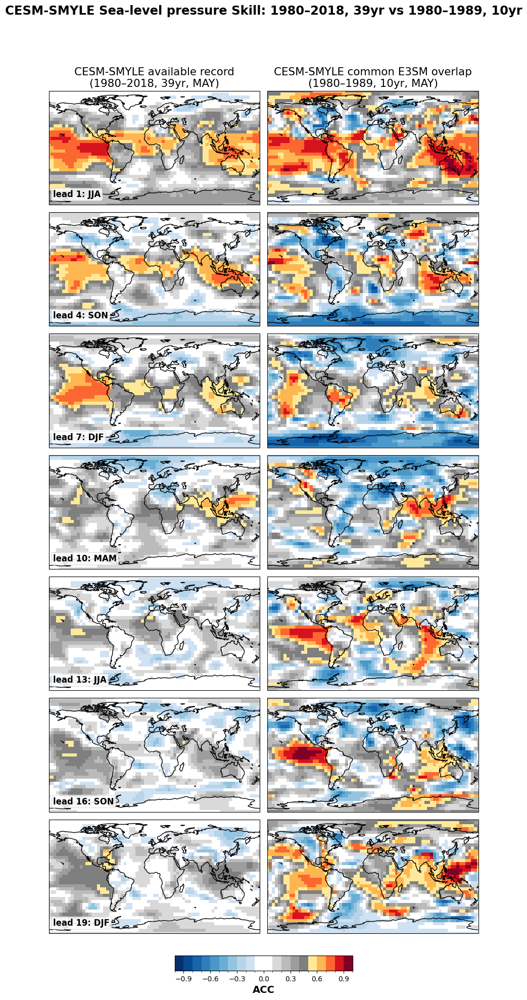

Closed workflow datasets and Dask resources.
CPU times: user 3.71 s, sys: 723 ms, total: 4.44 s
Wall time: 5.11 s


In [56]:
%%time
if not cfg.get("has_smyle_benchmark", True):
    print(f"Skipping the CESM-SMYLE sample-length comparison figure: no CESM-SMYLE benchmark is configured for field={field!r}.")
else:
    smyle_records = [
        ("CESM-SMYLE available record", smyle_skill_by_month, available_years),
        ("CESM-SMYLE common E3SM overlap", smyle_overlap_skill_by_month, overlap_years),
    ]

    plot_months = [
        month for month in init_months
        if all(month in record_by_month for _, record_by_month, _ in smyle_records)
    ]
    if not plot_months:
        raise RuntimeError("No CESM-SMYLE initialization months are available")
    plot_nlead = min(
        WORKFLOW_SETTINGS["final_acc_figures"]["max_leads"],
        *(record_by_month[month].sizes["L"]
          for _, record_by_month, _ in smyle_records
          for month in plot_months),
    )
    plot_leads = list(range(plot_nlead))

    if not plot_months or not plot_leads:
        raise RuntimeError("No CESM-SMYLE initialization months or leads are available.")

    nrows = len(plot_leads)
    ncols = len(plot_months) * len(smyle_records)
    fig = plt.figure(
        figsize=(
            final_geom_cfg["fig_col_width"] * ncols,
            final_geom_cfg["fig_row_height"] * nrows,
        )
    )

    first_month = plot_months[0]
    fig.suptitle(
        f"CESM-SMYLE {cfg['plot_name']} Skill: "
        f"{year_label(available_years(first_month))} vs "
        f"{year_label(overlap_years(first_month))}",
        fontsize=final_acc_style_cfg["fontz"] * 1.25,
        fontweight="bold",
        y=0.995,
    )

    proj = ccrs.PlateCarree()
    cntr = None

    for i, lead_index in enumerate(plot_leads):
        for j, init_month in enumerate(plot_months):
            for k, (record_name, record_by_month, years_function) in enumerate(smyle_records):
                skill_ds = record_by_month[init_month]
                subplot = i * ncols + j * len(smyle_records) + k + 1
                title = (
                    f"{record_name}\n"
                    f"({year_label(years_function(init_month))}, "
                    f"{init_month_names.get(init_month, f'{init_month:02d}')})"
                    if i == 0 else ""
                )

                ax, cntr = maps.map_pcolor_global_subplot(
                    fig,
                    skill_ds.corr.isel(L=lead_index),
                    skill_ds.lon,
                    skill_ds.lat,
                    acc_ci,
                    acc_cmin,
                    acc_cmax,
                    title,
                    nrows,
                    ncols,
                    subplot,
                    proj,
                    cmap=acc_cmap,
                    cutoff=acc_cutoff,
                    fontsize=final_acc_style_cfg["fontz"] * 1.1,
                )
                if k == 0:
                    display_lead = int(skill_ds.L.values[lead_index]) - 2
                    leadstr = f"lead {display_lead}: {seasonal_label(init_month, display_lead)}"
                    ax.text(
                        0.02, 0.05, leadstr,
                        fontsize=final_acc_style_cfg["fontz"] * 0.85,
                        fontweight="bold",
                        bbox=compare_label_bbox,
                        zorder=10,
                        transform=ax.transAxes,
                        ha="left", va="bottom",
                    )

    fig.tight_layout(rect=[0.0, 0.05, 1.0, 0.96])
    cbar_ax = fig.add_axes([0.3, 0.02, 0.4, 0.015])
    cbar = fig.colorbar(cntr, cax=cbar_ax, orientation="horizontal")
    cbar.set_label("ACC", fontsize=final_acc_style_cfg["fontz"], fontweight="bold")

    smyle_comp_figname = FIGURE_FILENAMES["distribution"]
    smyle_comp_figpath = FIGURE_OUTDIR / smyle_comp_figname
    full_labels = ", ".join(year_label(available_years(month)) for month in plot_months)
    overlap_labels = ", ".join(year_label(overlap_years(month)) for month in plot_months)

    mov.save_figure(
        fig,
        smyle_comp_figpath,
        mode="",
        metric="leadtime_acc_smyle_record_length",
        title=f"CESM-SMYLE Record Length Comparison: {field}",
        caption=(
            f"CESM-SMYLE available record ({full_labels}) versus "
            f"common E3SM overlap ({overlap_labels})"
        ),
        dpi=300,
    )
    print("Saved figure:", smyle_comp_figpath)
    plt.show()

# Release datasets, file managers, and Dask resources on normal completion.
close_notebook_resources(globals())
prepared_skill_datasets.clear()
print("Closed workflow datasets and Dask resources.")
